In [24]:
# ==============================================================================
# PHẦN 1: IMPORT THƯ VIỆN & ĐỌC DATASET & EDA CƠ BẢN (CẬP NHẬT CHO DATASET V2)
# ==============================================================================

import os
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

# Cấu hình giao diện đồ thị
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)
pd.set_option("display.max_columns", None)

# 1.1. Tự động tìm và đọc tập dữ liệu mới stroke_risk_dataset_v2.csv
possible_paths = [
    "stroke_risk_dataset_v2.csv",
    "../stroke_risk_dataset_v2.csv",
    "data/stroke_risk_dataset_v2.csv",
    "../data/stroke_risk_dataset_v2.csv",
]

df = None
for path in possible_paths:
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"✅ Đã tải thành công tập dữ liệu từ đường dẫn: '{path}'\n")
        break

if df is None:
    raise FileNotFoundError(
        "❌ Không tìm thấy file 'stroke_risk_dataset_v2.csv'! "
        "Vui lòng kiểm tra lại file đã nằm ở thư mục dự án chưa."
    )

# 1.2. Hiển thị 5 dòng đầu tiên
print("--- 5 DÒNG ĐẦU TIÊN CỦA DATASET ---")
display(df.head())

# 1.3. Kích thước dataset
print(f"\n--- KÍCH THƯỚC DATASET ---")
print(f"Số dòng (Rows): {df.shape[0]}")
print(f"Số cột (Columns): {df.shape[1]}")

# 1.4. Danh sách tên các cột
print("\n--- DANH SÁCH CÁC CỘT ---")
print(list(df.columns))

# 1.5. Kiểu dữ liệu và thông tin dataset
print("\n--- THÔNG TIN CHI TIẾT (df.info()) ---")
df.info()

# 1.6. Thống kê mô tả (Numerical Features)
print("\n--- THỐNG KÊ MÔ TẢ BIẾN SỐ (df.describe()) ---")
display(df.describe().T)

# 1.7. Thống kê mô tả (Categorical Features - Nếu có)
print("\n--- THỐNG KÊ MÔ TẢ BIẾN PHÂN LOẠI ---")
cat_cols = df.select_dtypes(include=["object"]).columns
if len(cat_cols) > 0:
    display(df.describe(include=["object"]).T)
else:
    print("Không có cột dữ liệu dạng chuỗi (Object). Tất cả đã được mã hóa dạng số.")

# 1.8. Kiểm tra giá trị Unique và Missing sơ bộ
print("\n--- EDA CƠ BẢN: MISSING, DUPLICATED & UNIQUE VALUES ---")
eda_summary = pd.DataFrame(
    {
        "Data Type": df.dtypes,
        "Missing Values": df.isnull().sum(),
        "Missing Ratio (%)": (df.isnull().sum() / len(df) * 100).round(2),
        "Unique Values": df.nunique(),
    }
)
display(eda_summary)

print(f"Số lượng dòng bị trùng lặp (Duplicated rows): {df.duplicated().sum()}")

# 1.9. Kiểm tra giá trị cụ thể của các cột quan trọng trong Dataset V2
print("\n--- KIỂM TRA ĐẶC BIỆT CÁC CỘT QUAN TRỌNG ---")
if 'age' in df.columns:
    print(f"1. Độ tuổi (Age): Min = {df['age'].min()}, Max = {df['age'].max()}")

# Kiểm tra nhãn nguy cơ (Target)
target_col = 'at_risk' if 'at_risk' in df.columns else ('stroke' if 'stroke' in df.columns else None)
if target_col:
    print(f"2. Phân bố nhãn Target ('{target_col}'):\n{df[target_col].value_counts()}")
    print(f"   Tỷ lệ Target:\n{(df[target_col].value_counts(normalize=True) * 100).round(2)}")

✅ Đã tải thành công tập dữ liệu từ đường dẫn: '../data/stroke_risk_dataset_v2.csv'

--- 5 DÒNG ĐẦU TIÊN CỦA DATASET ---


,age,gender,chest_pain,high_blood_pressure,irregular_heartbeat,shortness_of_breath,fatigue_weakness,dizziness,swelling_edema,neck_jaw_pain,excessive_sweating,persistent_cough,nausea_vomiting,chest_discomfort,cold_hands_feet,snoring_sleep_apnea,anxiety_doom,stroke_risk_percentage,at_risk
0,22,Male,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,33.3,0
1,52,Male,0,1,1,0,0,0,0,0,0,0,0,0,1,1,0,100.0,1
2,63,Female,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,100.0,1
3,41,Male,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,44.5,0
4,53,Male,0,0,0,0,0,1,1,0,0,0,1,0,1,0,0,84.8,1



--- KÍCH THƯỚC DATASET ---
Số dòng (Rows): 35000
Số cột (Columns): 19

--- DANH SÁCH CÁC CỘT ---
['age', 'gender', 'chest_pain', 'high_blood_pressure', 'irregular_heartbeat', 'shortness_of_breath', 'fatigue_weakness', 'dizziness', 'swelling_edema', 'neck_jaw_pain', 'excessive_sweating', 'persistent_cough', 'nausea_vomiting', 'chest_discomfort', 'cold_hands_feet', 'snoring_sleep_apnea', 'anxiety_doom', 'stroke_risk_percentage', 'at_risk']

--- THÔNG TIN CHI TIẾT (df.info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     35000 non-null  int64  
 1   gender                  35000 non-null  str    
 2   chest_pain              35000 non-null  int64  
 3   high_blood_pressure     35000 non-null  int64  
 4   irregular_heartbeat     35000 non-null  int64  
 5   shortness_of_breath     35000 non-null  int

,count,mean,std,min,25%,50%,75%,max
age,35000.0,38.630171,11.564128,18.0,30.0,37.0,46.0,86.0
chest_pain,35000.0,0.145857,0.352968,0.0,0.0,0.0,0.0,1.0
high_blood_pressure,35000.0,0.251914,0.434118,0.0,0.0,0.0,1.0,1.0
irregular_heartbeat,35000.0,0.098457,0.297936,0.0,0.0,0.0,0.0,1.0
shortness_of_breath,35000.0,0.190057,0.392352,0.0,0.0,0.0,0.0,1.0
fatigue_weakness,35000.0,0.244543,0.429822,0.0,0.0,0.0,0.0,1.0
dizziness,35000.0,0.190686,0.392847,0.0,0.0,0.0,0.0,1.0
swelling_edema,35000.0,0.145943,0.353054,0.0,0.0,0.0,0.0,1.0
neck_jaw_pain,35000.0,0.099514,0.299356,0.0,0.0,0.0,0.0,1.0
excessive_sweating,35000.0,0.097514,0.296661,0.0,0.0,0.0,0.0,1.0



--- THỐNG KÊ MÔ TẢ BIẾN PHÂN LOẠI ---


,count,unique,top,freq
gender,35000,2,Female,17528



--- EDA CƠ BẢN: MISSING, DUPLICATED & UNIQUE VALUES ---


,Data Type,Missing Values,Missing Ratio (%),Unique Values
age,int64,0,0.0,68
gender,str,0,0.0,2
chest_pain,int64,0,0.0,2
high_blood_pressure,int64,0,0.0,2
irregular_heartbeat,int64,0,0.0,2
shortness_of_breath,int64,0,0.0,2
fatigue_weakness,int64,0,0.0,2
dizziness,int64,0,0.0,2
swelling_edema,int64,0,0.0,2
neck_jaw_pain,int64,0,0.0,2


Số lượng dòng bị trùng lặp (Duplicated rows): 16279

--- KIỂM TRA ĐẶC BIỆT CÁC CỘT QUAN TRỌNG ---
1. Độ tuổi (Age): Min = 18, Max = 86
2. Phân bố nhãn Target ('at_risk'):
at_risk
0    22113
1    12887
Name: count, dtype: int64
   Tỷ lệ Target:
at_risk
0    63.18
1    36.82
Name: proportion, dtype: float64


2.1. KIỂM TRA VÀ XỬ LÝ MISSING VALUES
✅ Dataset v2 hoàn toàn không có giá trị bị thiếu (No Missing Values).

2.2. KIỂM TRA OUTLIERS CHO CÁC BIẾN SỐ LIÊN TỤC
Các biến số liên tục được kiểm tra Outliers: ['age', 'stroke_risk_percentage']

--- BẢNG THỐNG KÊ OUTLIERS THEO IQR ---


,Feature,Q1 (25%),Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Ratio (%)
0,age,30.0,46.0,16.0,6.0,70.0,238,0.68
1,stroke_risk_percentage,19.9,64.5,44.6,-47.0,131.4,0,0.00


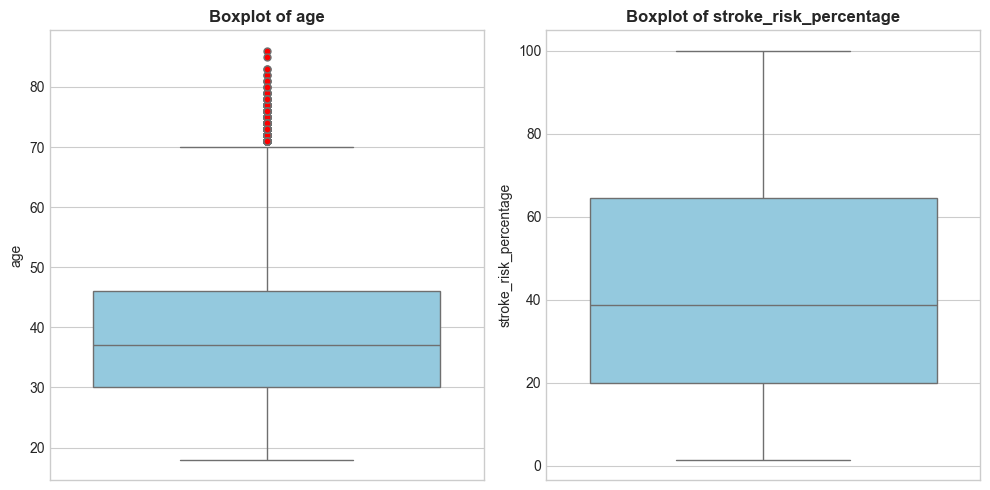


⚠️ KẾT LUẬN VỀ OUTLIER:
1. Tập dữ liệu v2 đã được làm sạch chuẩn hóa, các giá trị độ tuổi nằm trong khoảng sinh lý hợp lệ.
2. Tất cả các dữ liệu được giữ nguyên để phục vụ huấn luyện mô hình Machine Learning.


In [25]:
# ==============================================================================
# PHẦN 2: MISSING VALUES & OUTLIERS ANALYSIS (CẬP NHẬT CHO DATASET V2)
# ==============================================================================

# Tạo bản sao dataframe cho xử lý và làm sạch
df_clean = df.copy()

# ------------------------------------------------------------------------------
# 2.1. XỬ LÝ MISSING VALUES
# ------------------------------------------------------------------------------
print("==========================================")
print("2.1. KIỂM TRA VÀ XỬ LÝ MISSING VALUES")
print("==========================================")

# Xóa cột ID nếu có
df_clean = df_clean.drop(columns=["id", "Unnamed: 0"], errors="ignore")

# Kiểm tra số lượng và tỷ lệ missing values
missing_count = df_clean.isnull().sum()
missing_percent = (df_clean.isnull().sum() / len(df_clean)) * 100

missing_df = pd.DataFrame(
    {"Missing Count": missing_count, "Missing Ratio (%)": missing_percent}
).query("`Missing Count` > 0")

if len(missing_df) > 0:
    print("\n--- Danh sách các cột bị thiếu dữ liệu ---")
    display(missing_df)
    
    # Điền giá trị thiếu: Median cho cột số, Mode cho cột chuỗi
    num_cols = df_clean.select_dtypes(include=[np.number]).columns
    for col in num_cols:
        if df_clean[col].isnull().sum() > 0:
            df_clean[col] = df_clean[col].fillna(df_clean[col].median())
            
    cat_cols = df_clean.select_dtypes(include=['object', 'category']).columns
    for col in cat_cols:
        if df_clean[col].isnull().sum() > 0:
            df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])
    print("✅ Đã tự động xử lý toàn bộ giá trị bị thiếu (Missing Values).")
else:
    print("✅ Dataset v2 hoàn toàn không có giá trị bị thiếu (No Missing Values).")


# ------------------------------------------------------------------------------
# 2.2. PHÂN TÍCH VÀ KIỂM TRA OUTLIERS (IQR METHOD)
# ------------------------------------------------------------------------------
print("\n==========================================")
print("2.2. KIỂM TRA OUTLIERS CHO CÁC BIẾN SỐ LIÊN TỤC")
print("==========================================")

def detect_outliers_iqr(dataframe, features):
    outlier_summary = []
    for col in features:
        Q1 = dataframe[col].quantile(0.25)
        Q3 = dataframe[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        outliers = dataframe[(dataframe[col] < lower_bound) | (dataframe[col] > upper_bound)]
        outlier_count = len(outliers)
        outlier_ratio = (outlier_count / len(dataframe)) * 100

        outlier_summary.append(
            {
                "Feature": col,
                "Q1 (25%)": round(Q1, 2),
                "Q3 (75%)": round(Q3, 2),
                "IQR": round(IQR, 2),
                "Lower Bound": round(lower_bound, 2),
                "Upper Bound": round(upper_bound, 2),
                "Outlier Count": outlier_count,
                "Outlier Ratio (%)": round(outlier_ratio, 2),
            }
        )
    return pd.DataFrame(outlier_summary)

# Lọc danh sách các biến số liên tục (nunique > 2, loại bỏ target)
continuous_features = [
    col for col in df_clean.select_dtypes(include=[np.number]).columns 
    if df_clean[col].nunique() > 2 and col not in ['at_risk', 'stroke']
]

print(f"Các biến số liên tục được kiểm tra Outliers: {continuous_features}")

if len(continuous_features) > 0:
    outlier_df = detect_outliers_iqr(df_clean, continuous_features)
    print("\n--- BẢNG THỐNG KÊ OUTLIERS THEO IQR ---")
    display(outlier_df)

    # 2.3. TRỰC QUAN HÓA OUTLIERS BẰNG BOXPLOT
    num_plots = len(continuous_features)
    fig, axes = plt.subplots(1, num_plots, figsize=(max(5 * num_plots, 6), 5))
    if num_plots == 1:
        axes = [axes]

    for i, col in enumerate(continuous_features):
        sns.boxplot(
            y=df_clean[col], 
            ax=axes[i], 
            color="skyblue", 
            flierprops={"markerfacecolor": "red", "markersize": 5}
        )
        axes[i].set_title(f"Boxplot of {col}", fontsize=12, fontweight="bold")
        axes[i].set_ylabel(col, fontsize=10)

    plt.tight_layout()
    plt.show()

print("\n⚠️ KẾT LUẬN VỀ OUTLIER:")
print("1. Tập dữ liệu v2 đã được làm sạch chuẩn hóa, các giá trị độ tuổi nằm trong khoảng sinh lý hợp lệ.")
print("2. Tất cả các dữ liệu được giữ nguyên để phục vụ huấn luyện mô hình Machine Learning.")

3.1. PHÂN TÍCH PHÂN BỐ NHÃN TARGET ('AT_RISK')
Số lượng at_risk = 0 (Không nguy cơ): 22113
Số lượng at_risk = 1 (Có nguy cơ)   : 12887
Tỷ lệ at_risk = 0                   : 63.18%
Tỷ lệ at_risk = 1                   : 36.82%


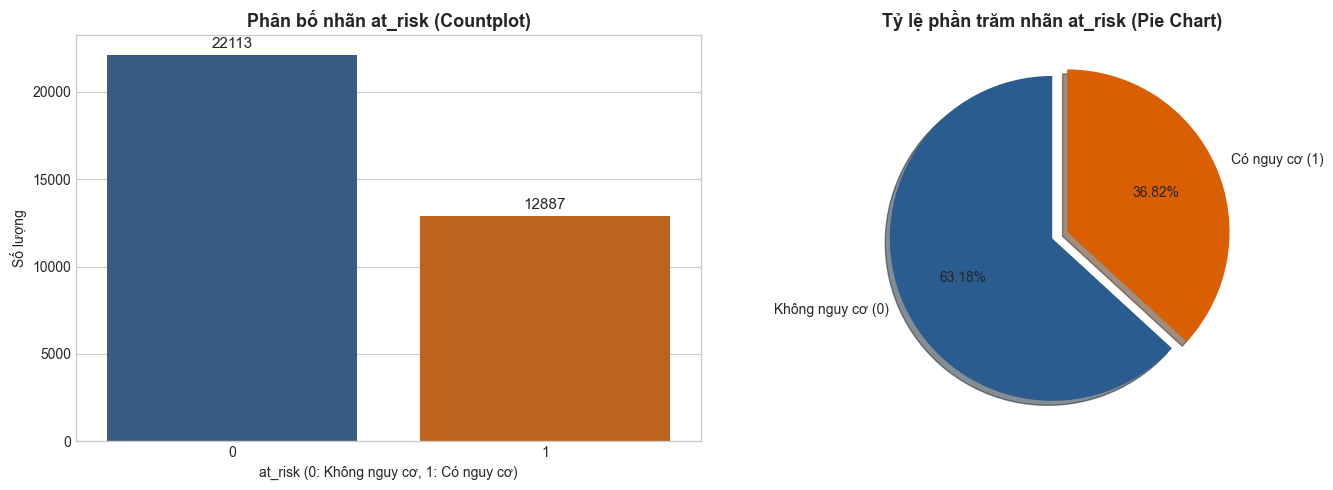


3.2. TRỰC QUAN HÓA CHI TIẾT CÁC ĐẶC TRƯNG


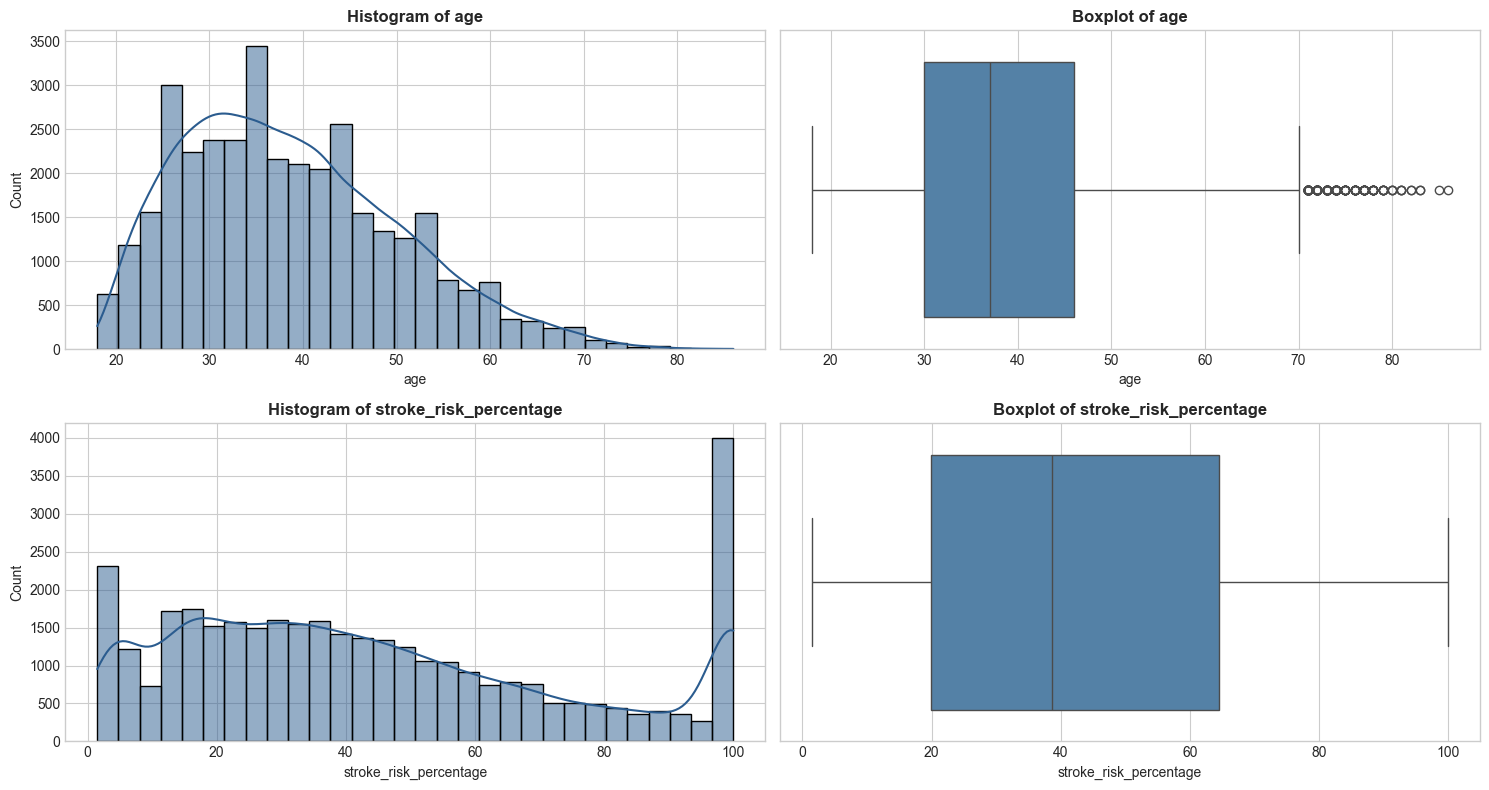

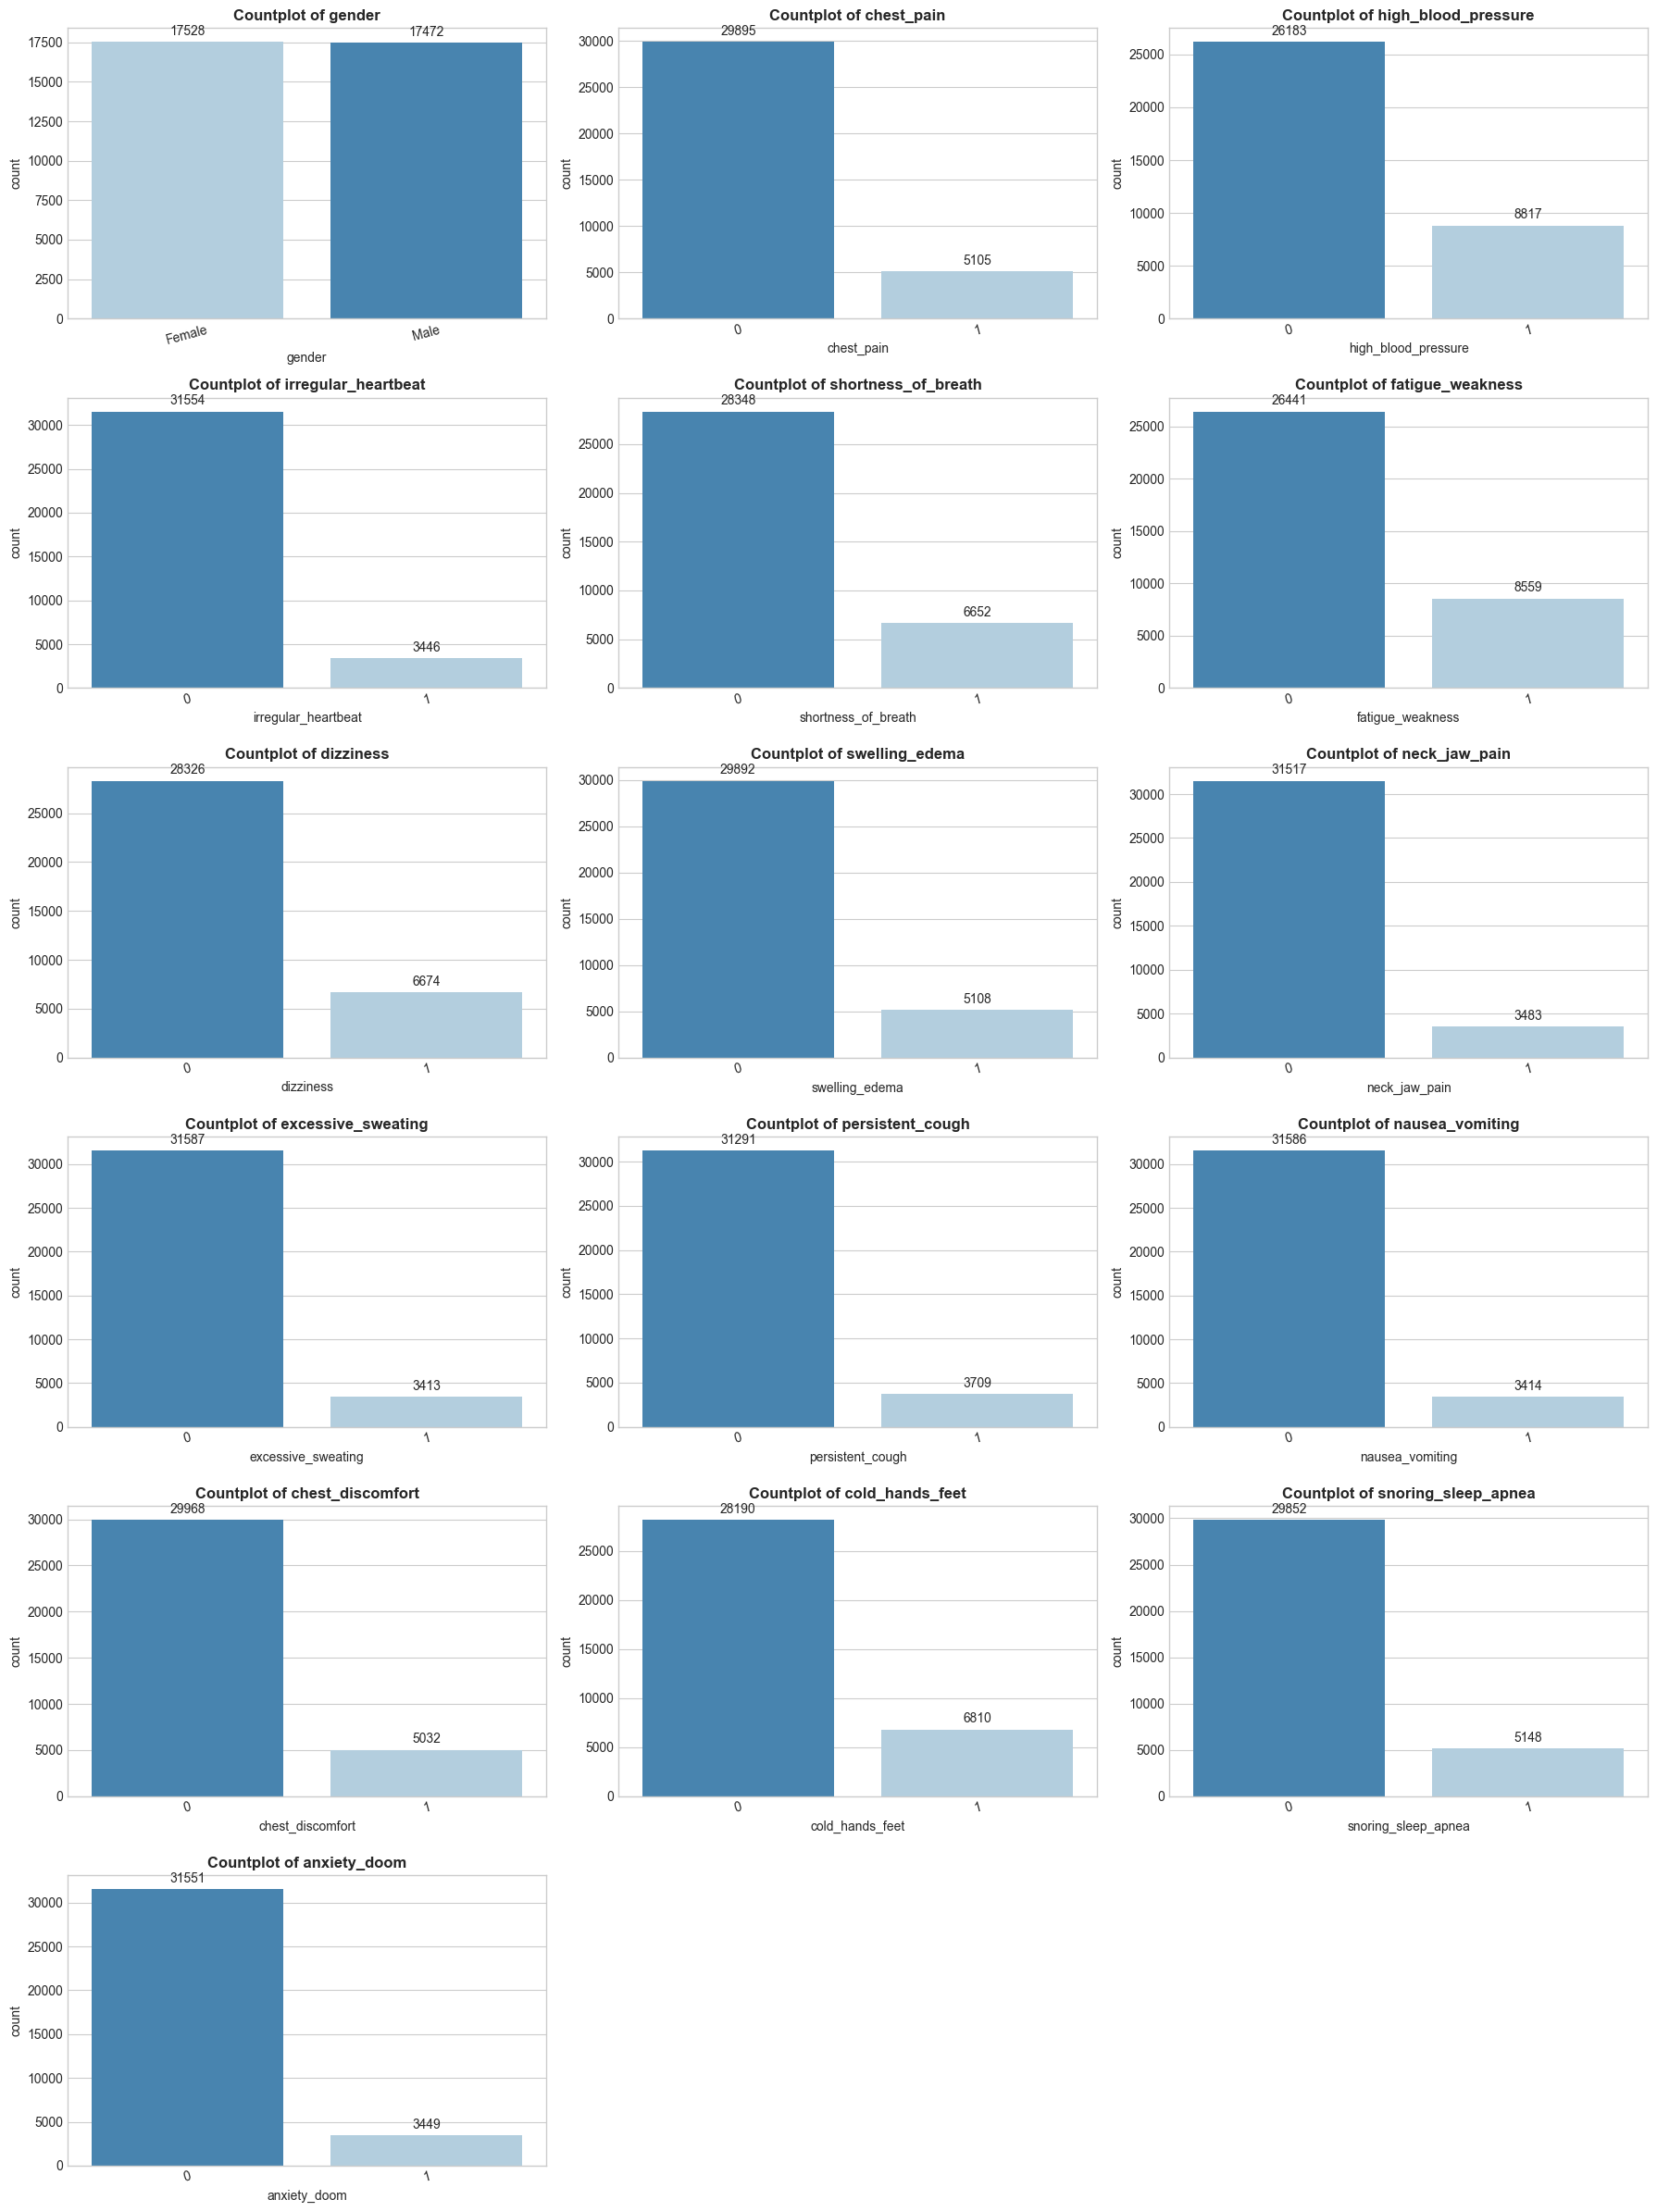


3.3. SO SÁNH CÁC BIẾN ĐẦU VÀO VỚI 'AT_RISK'


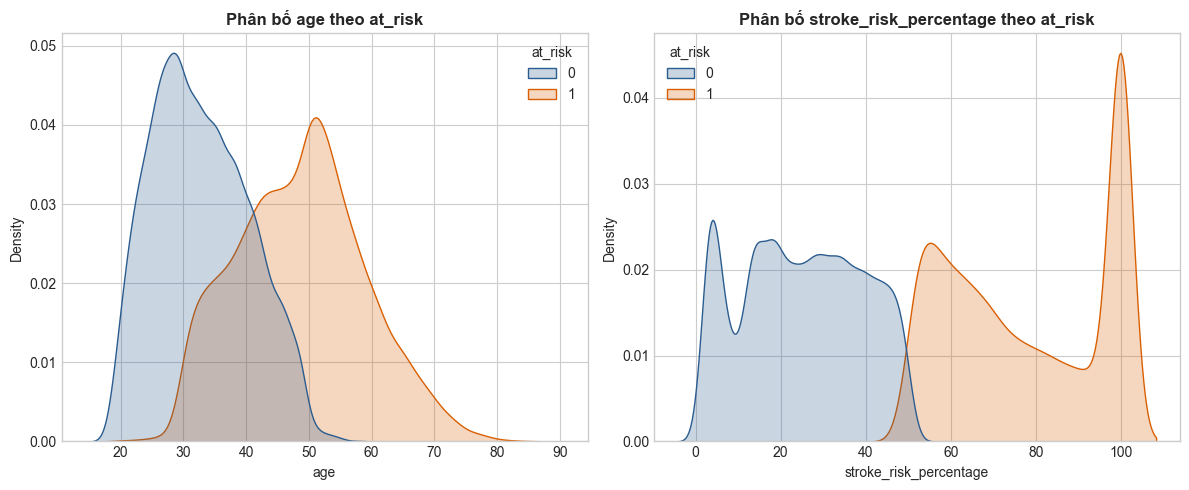

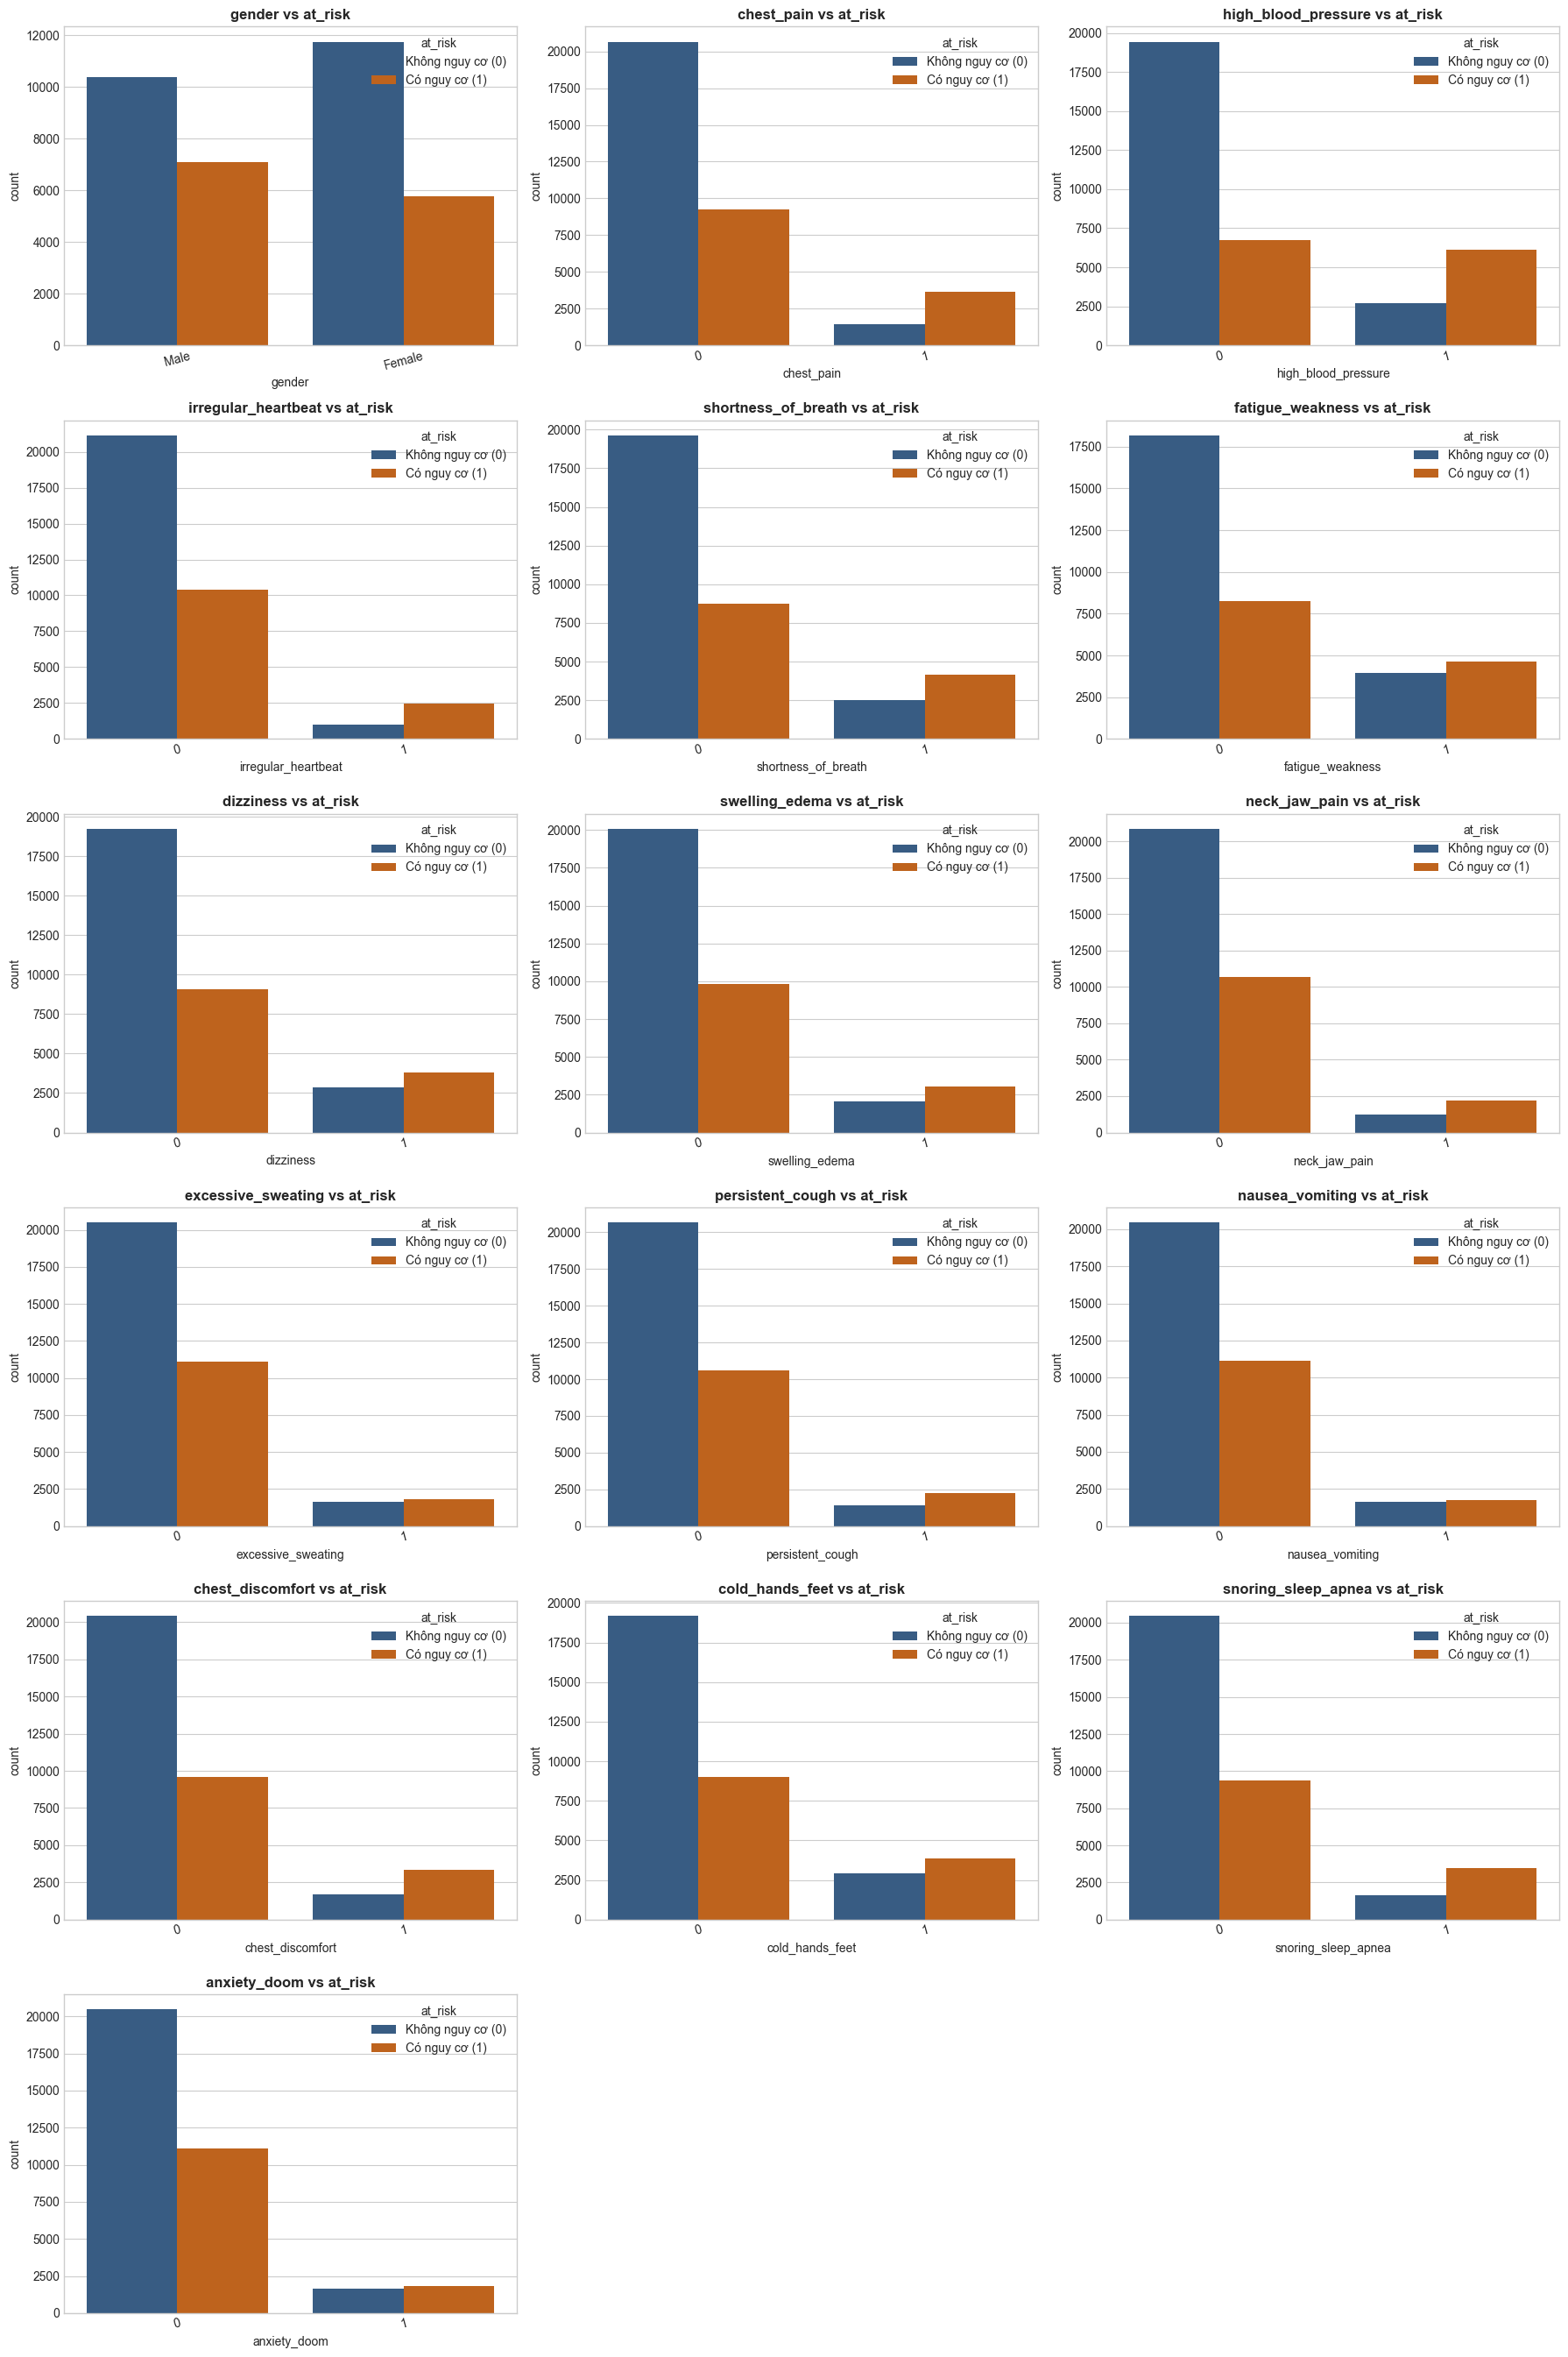

In [26]:
# ==============================================================================
# PHẦN 3: TRỰC QUAN HÓA DỮ LIỆU (VISUALIZATION & CLASS DISTRIBUTION)
# ==============================================================================

palette = ["#2b5c8f", "#d95f02"]

# Tự động xác định tên cột Target
target_col = 'at_risk' if 'at_risk' in df_clean.columns else ('stroke' if 'stroke' in df_clean.columns else df_clean.columns[-1])

# ------------------------------------------------------------------------------
# 3.1. PHÂN TÍCH VÀ TRỰC QUAN HÓA PHÂN BỐ NHÃN (CLASS IMBALANCE)
# ------------------------------------------------------------------------------
print("==========================================")
print(f"3.1. PHÂN TÍCH PHÂN BỐ NHÃN TARGET ('{target_col.upper()}')")
print("==========================================")

stroke_counts = df_clean[target_col].value_counts()
stroke_percentages = df_clean[target_col].value_counts(normalize=True) * 100

val_0 = stroke_counts.get(0, 0)
val_1 = stroke_counts.get(1, 0)
pct_0 = stroke_percentages.get(0, 0.0)
pct_1 = stroke_percentages.get(1, 0.0)

print(f"Số lượng {target_col} = 0 (Không nguy cơ): {val_0}")
print(f"Số lượng {target_col} = 1 (Có nguy cơ)   : {val_1}")
print(f"Tỷ lệ {target_col} = 0                   : {pct_0:.2f}%")
print(f"Tỷ lệ {target_col} = 1                   : {pct_1:.2f}%")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Countplot
sns.countplot(x=target_col, data=df_clean, ax=ax[0], hue=target_col, palette=palette, legend=False)
ax[0].set_title(f"Phân bố nhãn {target_col} (Countplot)", fontsize=13, fontweight="bold")
ax[0].set_xlabel(f"{target_col} (0: Không nguy cơ, 1: Có nguy cơ)")
ax[0].set_ylabel("Số lượng")

for p in ax[0].patches:
    height = p.get_height()
    if height > 0:
        ax[0].annotate(
            f"{int(height)}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center", va="bottom", fontsize=11, xytext=(0, 3), textcoords="offset points"
        )

# Pie chart
ax[1].pie(
    [val_0, val_1],
    labels=["Không nguy cơ (0)", "Có nguy cơ (1)"],
    colors=palette,
    autopct="%1.2f%%",
    explode=[0, 0.1],
    startangle=90,
    shadow=True,
)
ax[1].set_title(f"Tỷ lệ phần trăm nhãn {target_col} (Pie Chart)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 3.2. TRỰC QUAN HÓA CÁC ĐẶC TRƯNG CHÍNH (SINGLE FEATURES DISTRIBUTION)
# ------------------------------------------------------------------------------
print("\n==========================================")
print("3.2. TRỰC QUAN HÓA CHI TIẾT CÁC ĐẶC TRƯNG")
print("==========================================")

num_cols = [
    col for col in df_clean.select_dtypes(include=[np.number]).columns 
    if df_clean[col].nunique() > 5 and col != target_col
]

cat_cols = [
    col for col in df_clean.columns 
    if (df_clean[col].nunique() <= 5 or df_clean[col].dtype == 'object') and col != target_col
]

# A. Trực quan biến định lượng liên tục
if len(num_cols) > 0:
    fig, axes = plt.subplots(len(num_cols), 2, figsize=(15, 4 * len(num_cols)))
    if len(num_cols) == 1:
        axes = np.expand_dims(axes, axis=0)

    for i, col in enumerate(num_cols):
        sns.histplot(df_clean[col], kde=True, ax=axes[i, 0], color="#2b5c8f", bins=30)
        axes[i, 0].set_title(f"Histogram of {col}", fontsize=12, fontweight="bold")

        sns.boxplot(x=df_clean[col], ax=axes[i, 1], color="#4682b4")
        axes[i, 1].set_title(f"Boxplot of {col}", fontsize=12, fontweight="bold")

    plt.tight_layout()
    plt.show()

# B. Trực quan biến định tính / phân loại
if len(cat_cols) > 0:
    n_cats = len(cat_cols)
    n_cols_plot = 3
    n_rows_plot = (n_cats + n_cols_plot - 1) // n_cols_plot

    fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(18, 4 * n_rows_plot))
    axes = np.array(axes).flatten() if n_cats > 1 else np.array([axes])

    for i, col in enumerate(cat_cols):
        sns.countplot(
            x=col,
            data=df_clean,
            ax=axes[i],
            hue=col,
            palette="Blues_r",
            legend=False,
            order=df_clean[col].value_counts().index,
        )
        axes[i].set_title(f"Countplot of {col}", fontsize=12, fontweight="bold")
        axes[i].tick_params(axis="x", rotation=15)
        for p in axes[i].patches:
            h = p.get_height()
            if h > 0:
                axes[i].annotate(
                    f"{int(h)}",
                    (p.get_x() + p.get_width() / 2.0, h),
                    ha="center", va="bottom", xytext=(0, 3), textcoords="offset points"
                )

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------------------------
# 3.3. SO SÁNH CÁC BIẾN ĐẦU VÀO VỚI TARGET
# ------------------------------------------------------------------------------
print("\n==========================================")
print(f"3.3. SO SÁNH CÁC BIẾN ĐẦU VÀO VỚI '{target_col.upper()}'")
print("==========================================")

# A. Biến số so sánh với Target
if len(num_cols) > 0:
    fig, axes = plt.subplots(1, len(num_cols), figsize=(max(6 * len(num_cols), 6), 5))
    if len(num_cols) == 1:
        axes = [axes]

    for i, col in enumerate(num_cols):
        sns.kdeplot(
            data=df_clean,
            x=col,
            hue=target_col,
            common_norm=False,
            palette=palette,
            ax=axes[i],
            fill=True,
        )
        axes[i].set_title(f"Phân bố {col} theo {target_col}", fontsize=12, fontweight="bold")

    plt.tight_layout()
    plt.show()

# B. Biến phân loại so sánh với Target
if len(cat_cols) > 0:
    n_cats = len(cat_cols)
    n_cols_plot = 3
    n_rows_plot = (n_cats + n_cols_plot - 1) // n_cols_plot

    fig, axes = plt.subplots(n_rows_plot, n_cols_plot, figsize=(18, 4.5 * n_rows_plot))
    axes = np.array(axes).flatten() if n_cats > 1 else np.array([axes])

    for i, col in enumerate(cat_cols):
        sns.countplot(
            x=col,
            hue=target_col,
            data=df_clean,
            ax=axes[i],
            palette=palette,
        )
        axes[i].set_title(f"{col} vs {target_col}", fontsize=12, fontweight="bold")
        axes[i].tick_params(axis="x", rotation=15)
        axes[i].legend(title=target_col, labels=["Không nguy cơ (0)", "Có nguy cơ (1)"], loc="upper right")

    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

✅ Đang sử dụng cột target: 'at_risk'

4.1. TRỰC QUAN HÓA CORRELATION MATRIX


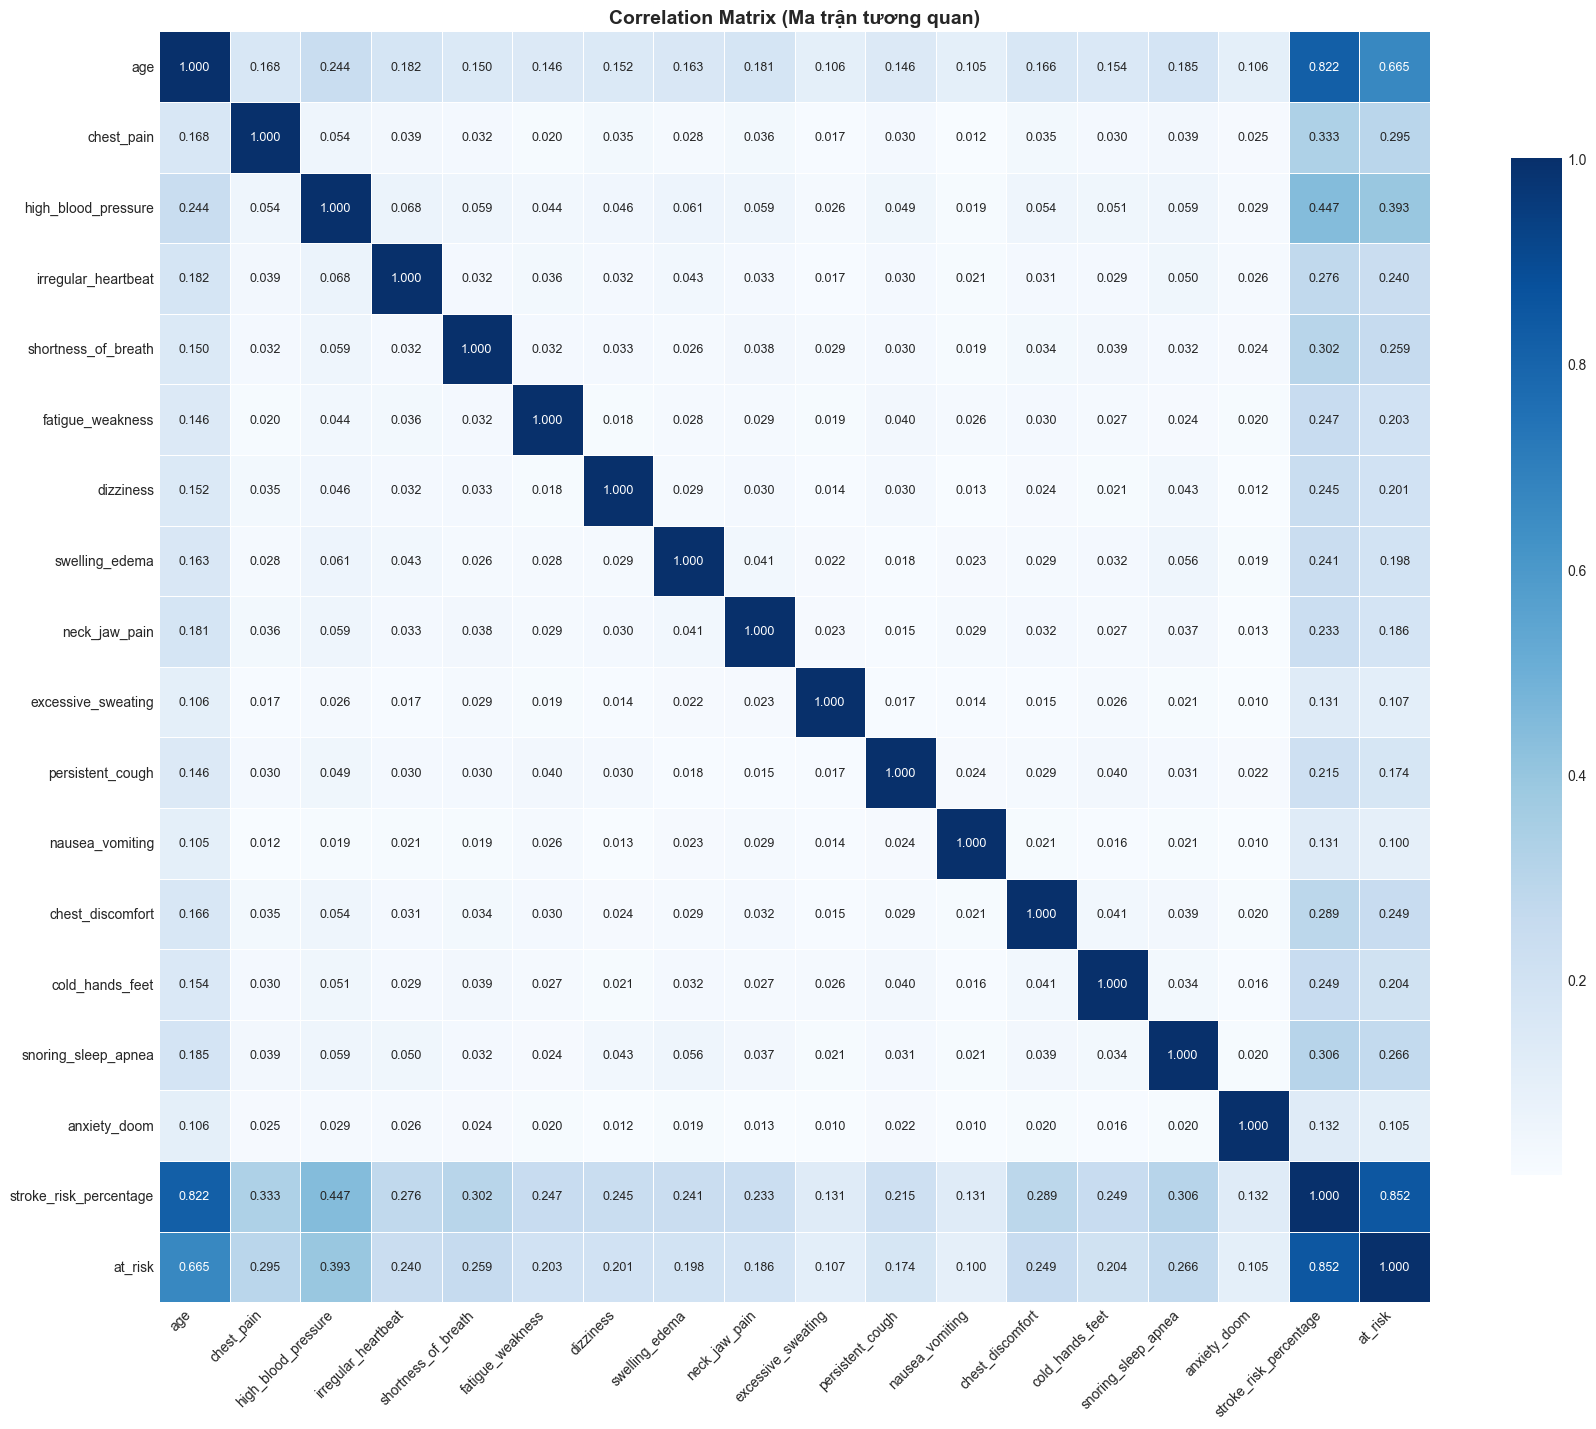


--- Nhận xét tương quan với biến target 'at_risk' ---
                        Hệ số tương quan
at_risk                         1.000000
stroke_risk_percentage          0.852185
age                             0.664524
high_blood_pressure             0.393487
chest_pain                      0.295271
snoring_sleep_apnea             0.266177
shortness_of_breath             0.258746
chest_discomfort                0.248903
irregular_heartbeat             0.239826
cold_hands_feet                 0.204342
fatigue_weakness                0.202815
dizziness                       0.200802
swelling_edema                  0.198199
neck_jaw_pain                   0.186125
persistent_cough                0.173854
excessive_sweating              0.107098
anxiety_doom                    0.104957
nausea_vomiting                 0.100022

4.2. TÍNH FEATURE IMPORTANCE TỪ TREE-BASED MODELS
  → Đang huấn luyện Decision Tree...
  → Đang huấn luyện Random Forest...
  → Đang huấn luyện AdaBoost...
  → Đang 

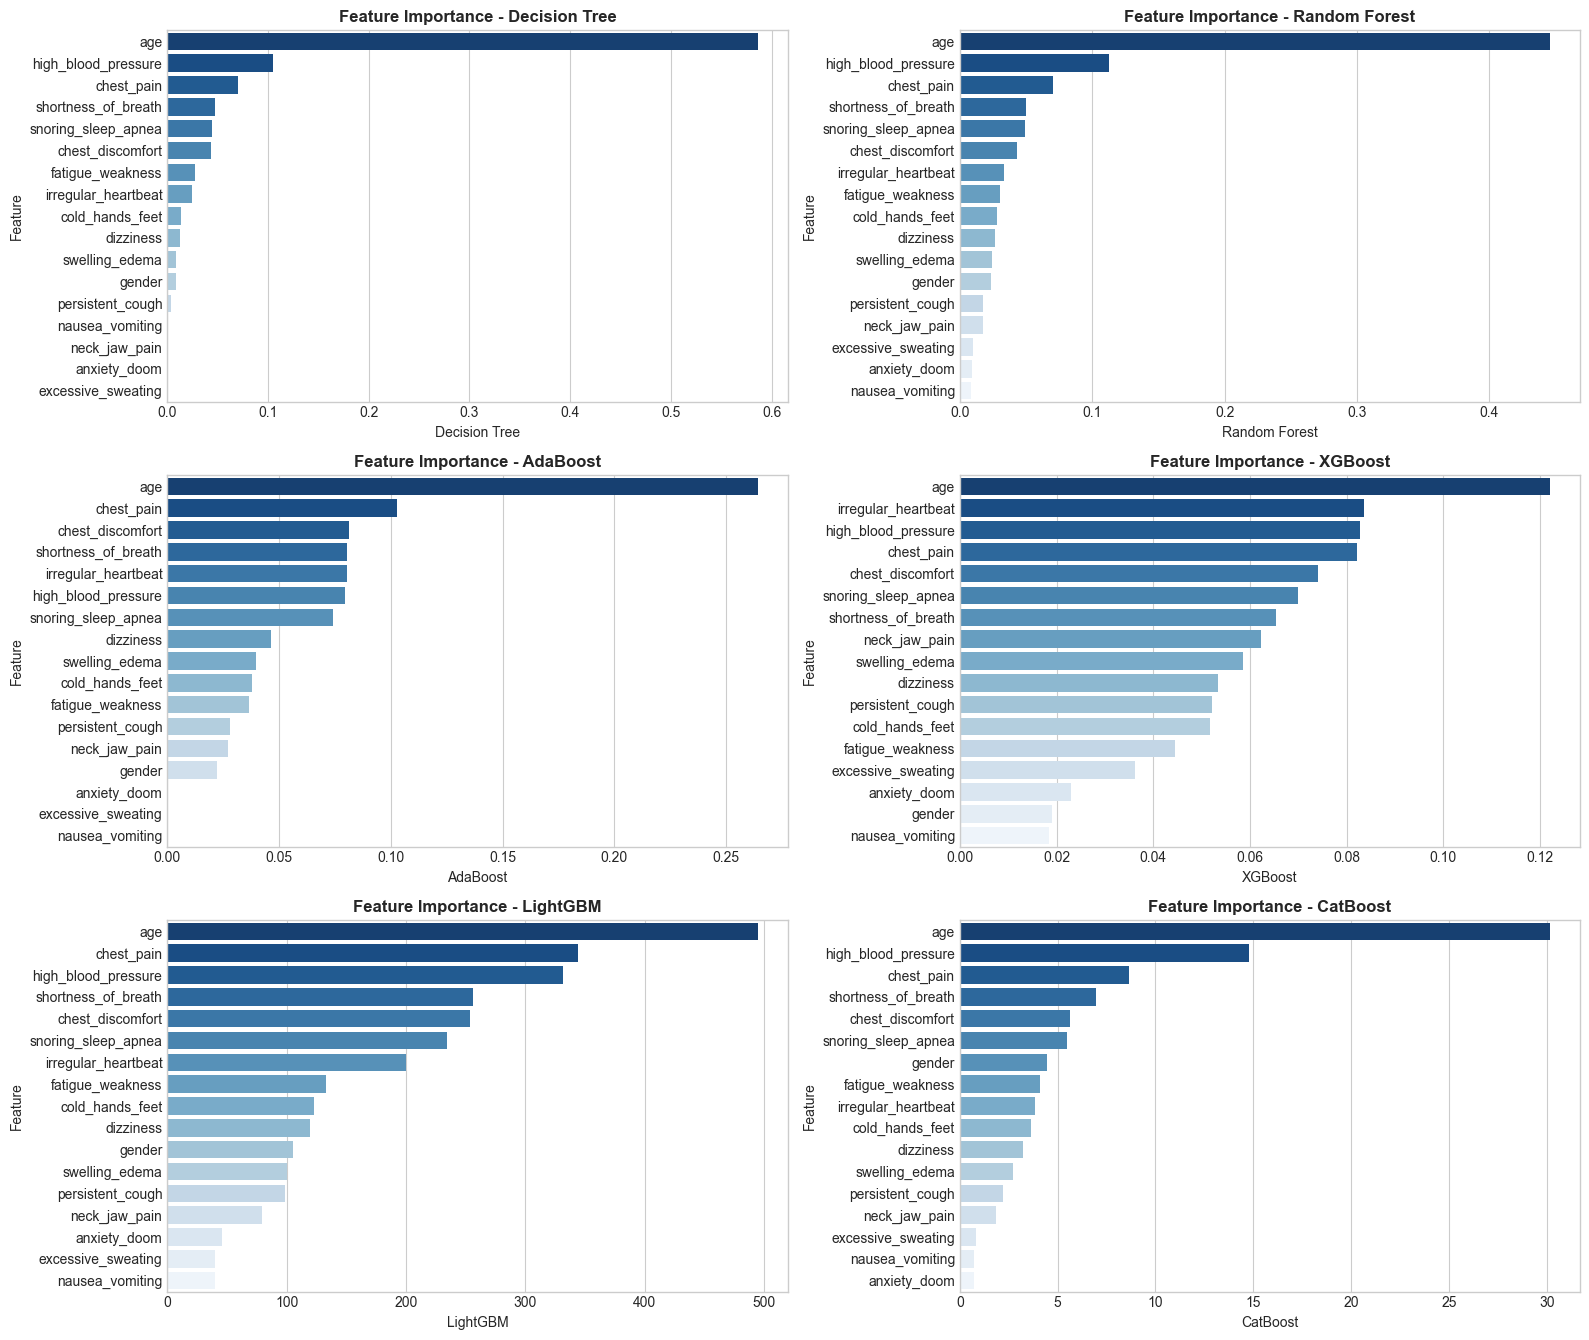

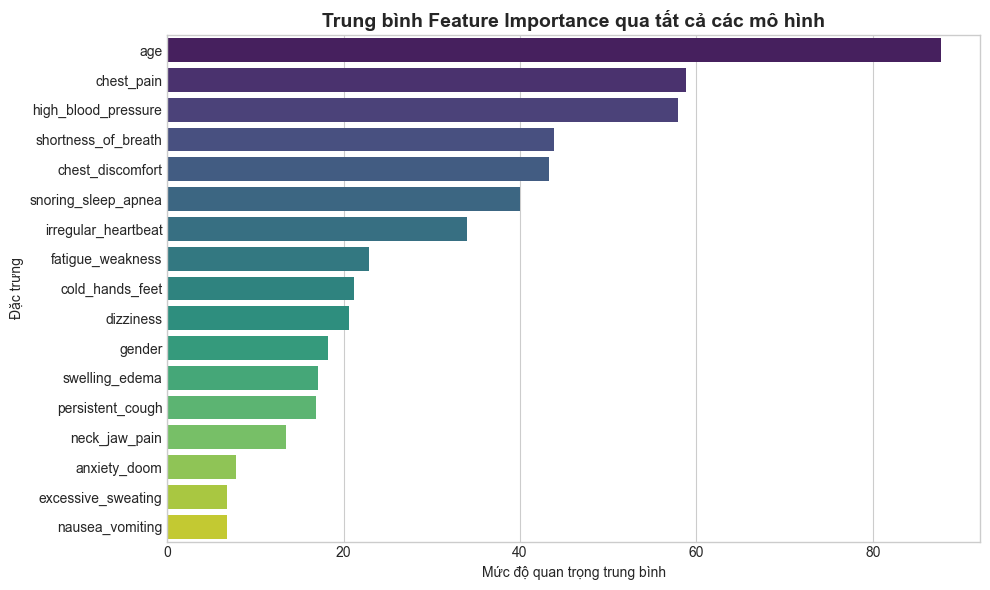

In [27]:
# ==============================================================================
# PHẦN 4: CORRELATION MATRIX & FEATURE IMPORTANCE
# ==============================================================================

from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None

try:
    from catboost import CatBoostClassifier
except ImportError:
    CatBoostClassifier = None

target_df = df_clean if "df_clean" in globals() else df

if "at_risk" in target_df.columns:
    TARGET_COL = "at_risk"
elif "stroke" in target_df.columns:
    TARGET_COL = "stroke"
else:
    TARGET_COL = target_df.columns[-1]

print(f"✅ Đang sử dụng cột target: '{TARGET_COL}'")

# ------------------------------------------------------------------------------
# 4.1. CORRELATION MATRIX
# ------------------------------------------------------------------------------
print("\n==========================================")
print("4.1. TRỰC QUAN HÓA CORRELATION MATRIX")
print("==========================================")

numeric_cols = target_df.select_dtypes(include=[np.number]).columns.tolist()
numeric_cols = [c for c in numeric_cols if c.lower() not in ["id", "unnamed: 0"]]

if TARGET_COL not in numeric_cols:
    numeric_cols.append(TARGET_COL)

corr_features = [c for c in numeric_cols if target_df[c].nunique() > 1 or c == TARGET_COL]
corr_matrix = target_df[corr_features].corr()

plt.figure(figsize=(max(8, len(corr_features)), max(6, len(corr_features) * 0.8)))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    annot_kws={"size": 9},
)
plt.title("Correlation Matrix (Ma trận tương quan)", fontsize=14, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"\n--- Nhận xét tương quan với biến target '{TARGET_COL}' ---")
print(corr_matrix[TARGET_COL].sort_values(ascending=False).to_frame(name="Hệ số tương quan"))

# ------------------------------------------------------------------------------
# 4.2. FEATURE IMPORTANCE TỪ TREE-BASED MODELS
# ------------------------------------------------------------------------------
print("\n==========================================")
print("4.2. TÍNH FEATURE IMPORTANCE TỪ TREE-BASED MODELS")
print("==========================================")

df_tree = target_df.drop(columns=["id", "Unnamed: 0"], errors="ignore").copy()
cat_cols = df_tree.select_dtypes(include=["object", "category"]).columns.tolist()

if len(cat_cols) > 0:
    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    df_tree[cat_cols] = encoder.fit_transform(df_tree[cat_cols].astype(str))

X_temp = df_tree.drop(columns=[TARGET_COL, "stroke_risk_percentage"], errors="ignore")
y_temp = df_tree[TARGET_COL]

X_temp = X_temp.apply(pd.to_numeric, errors="coerce")
imputer = SimpleImputer(strategy="median")
X_temp_imputed = pd.DataFrame(imputer.fit_transform(X_temp), columns=X_temp.columns)

tree_models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100, n_jobs=-1),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss", verbosity=0),
}

if LGBMClassifier:
    tree_models["LightGBM"] = LGBMClassifier(random_state=42, verbose=-1, n_jobs=-1)
if CatBoostClassifier:
    tree_models["CatBoost"] = CatBoostClassifier(random_state=42, verbose=0, thread_count=-1)

importance_dict = {"Feature": X_temp_imputed.columns}

for name, model in tree_models.items():
    print(f"  → Đang huấn luyện {name}...")
    model.fit(X_temp_imputed, y_temp)
    importance_dict[name] = model.feature_importances_

importance_df = pd.DataFrame(importance_dict)
importance_df["Trung bình"] = importance_df.drop(columns=["Feature"]).mean(axis=1)
importance_df = importance_df.sort_values("Trung bình", ascending=False)

print("\n--- Bảng Feature Importance (đã sắp xếp theo trung bình) ---")
print(importance_df.round(4).to_string(index=False))

# ------------------------------------------------------------------------------
# 4.3 & 4.4. TRỰC QUAN HÓA FEATURE IMPORTANCE
# ------------------------------------------------------------------------------
n_models = len(tree_models)
n_rows = (n_models + 1) // 2

fig, axes = plt.subplots(n_rows, 2, figsize=(16, 4.5 * n_rows))
axes = axes.flatten()

for idx, name in enumerate(tree_models.keys()):
    sorted_df = importance_df[["Feature", name]].sort_values(by=name, ascending=False)
    sns.barplot(
        x=name,
        y="Feature",
        data=sorted_df,
        ax=axes[idx],
        hue="Feature",
        palette="Blues_r",
        legend=False,
    )
    axes[idx].set_title(f"Feature Importance - {name}", fontsize=12, fontweight="bold")

if len(tree_models) < len(axes):
    for j in range(len(tree_models), len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(
    x="Trung bình",
    y="Feature",
    data=importance_df,
    palette="viridis",
    hue="Feature",
    legend=False,
)
plt.title("Trung bình Feature Importance qua tất cả các mô hình", fontsize=14, fontweight="bold")
plt.xlabel("Mức độ quan trọng trung bình")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

In [28]:
# ==============================================================================
# PHẦN 5: TIỀN XỬ LÝ DỮ LIỆU (PREPROCESSING PIPELINE)
# ==============================================================================

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

print("==========================================")
print("5. KHỞI TẠO COLUMN TRANSFORMER CHUẨN XỬ LÝ DỮ LIỆU")
print("==========================================")

# Pipeline tiền xử lý cho biến số
num_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

# Pipeline tiền xử lý cho biến phân loại
cat_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]
)

print("✅ Pipelines đã sẵn sàng cho bước ghép ghép với Mô hình Huấn Luyện.")

5. KHỞI TẠO COLUMN TRANSFORMER CHUẨN XỬ LÝ DỮ LIỆU
✅ Pipelines đã sẵn sàng cho bước ghép ghép với Mô hình Huấn Luyện.


In [29]:
# ==============================================================================
# PHẦN 6: BASELINE HUẤN LUYỆN CHO CÁC MODEL MACHINE LEARNING
# ==============================================================================

import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# Import Models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# 6.0. ĐỒNG BỘ TARGET & SPLIT DATA
target_df = df_clean if "df_clean" in globals() else df

if "at_risk" in target_df.columns:
    TARGET_COL = "at_risk"
elif "stroke" in target_df.columns:
    TARGET_COL = "stroke"
else:
    TARGET_COL = target_df.columns[-1]

X = target_df.drop(columns=[TARGET_COL, "stroke_risk_percentage", "id", "Unnamed: 0"], errors="ignore")
y = target_df[TARGET_COL].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Tự động cấu hình lại Preprocessor phù hợp đúng cột của X_train
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_transformer, num_cols),
        ("cat", cat_transformer, cat_cols),
    ]
)

# 6.1. DICTIONARY MÔ HÌNH BASELINE
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / max(pos_count, 1)

raw_models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000, class_weight="balanced"),
    "Gaussian Naive Bayes": GaussianNB(),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(random_state=42, class_weight="balanced", n_jobs=-1),
    "Support Vector Machine": SVC(probability=True, random_state=42, class_weight="balanced"),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss", scale_pos_weight=scale_pos_weight),
    "LightGBM": LGBMClassifier(random_state=42, verbose=-1, class_weight="balanced"),
    "CatBoost": CatBoostClassifier(random_state=42, verbose=0, auto_class_weights="Balanced"),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "MLP Classifier": MLPClassifier(random_state=42, max_iter=500),
}
SELECTED_MODELS = [
    "Logistic Regression",   # họ tuyến tính
    "Decision Tree",         # cây quyết định
    "Random Forest",         # bagging
    "XGBoost",               # boosting
    "MLP Classifier",        # mạng nơ-ron
]
raw_models = {k: v for k, v in raw_models.items() if k in SELECTED_MODELS}

# 6.2. HUẤN LUYỆN VÀ ĐÁNH GIÁ
os.makedirs("models", exist_ok=True)

baseline_results = []
fitted_baseline_pipelines = {}

for name, model in raw_models.items():
    try:
        pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", model)])
        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)
        if hasattr(pipeline, "predict_proba"):
            y_proba = pipeline.predict_proba(X_test)[:, 1]
        else:
            y_proba = pipeline.decision_function(X_test)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_test, y_proba)
        pr_auc = average_precision_score(y_test, y_proba)

        baseline_results.append({
            "Model": name,
            "Accuracy": round(acc, 4),
            "Precision": round(prec, 4),
            "Recall": round(rec, 4),
            "F1": round(f1, 4),
            "ROC-AUC": round(roc_auc, 4),
            "PR-AUC": round(pr_auc, 4),
        })

        fitted_baseline_pipelines[name] = pipeline

        filename = name.lower().replace(" ", "_").replace("-", "_")
        joblib.dump(pipeline, f"models/{filename}.pkl")
        print(f"✔️ Đã lưu: models/{filename}.pkl | PR-AUC={pr_auc:.4f} | Recall={rec:.4f}")

    except Exception as e:
        print(f"⚠️ Bỏ qua '{name}': {type(e).__name__}: {e}")

# 6.3. XUẤT BẢNG KẾT QUẢ
df_baseline = pd.DataFrame(baseline_results).sort_values(by=["PR-AUC", "F1"], ascending=False).reset_index(drop=True)
display(df_baseline)
df_baseline.to_csv("models/model_comparison.csv", index=False)

# 6.4. LỰA CHỌN MÔ HÌNH TỐT NHẤT & LƯU VÀO STACK
# best_model_name = df_baseline.iloc[0]["Model"]
# best_pipeline = fitted_baseline_pipelines[best_model_name]
# joblib.dump(best_pipeline, "models/stroke_model.pkl")

# print(f"\n🏆 Model tốt nhất theo PR-AUC: {best_model_name} -> Đã lưu vào models/stroke_model.pkl")

# 6.5. TÌM NGƯỠNG TỐI ƯU & LƯU THRESHOLD JSON
# y_proba_best = best_pipeline.predict_proba(X_test)[:, 1]
# precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba_best)
# f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
# best_threshold = float(thresholds[np.argmax(f1_scores[:-1])])

# with open("models/threshold.json", "w", encoding="utf-8") as f:
#     json.dump({"threshold": best_threshold}, f, ensure_ascii=False, indent=2)

# 6.6. LƯU THÔNG TIN TỔNG QUAN (SUMMARY JSON)
# summary_data = {
#     "target_column": TARGET_COL,
#     "n_samples": int(len(target_df)),
#     "n_features": int(X_train.shape[1]),
#     "n_train": int(len(X_train)),
#     "n_test": int(len(X_test)),
#     "best_model": best_model_name,
#     "threshold": best_threshold,
#     "metrics": {
#         "Accuracy": float(df_baseline.iloc[0]["Accuracy"]),
#         "Precision": float(df_baseline.iloc[0]["Precision"]),
#         "Recall": float(df_baseline.iloc[0]["Recall"]),
#         "F1": float(df_baseline.iloc[0]["F1"]),
#         "ROC-AUC": float(df_baseline.iloc[0]["ROC-AUC"]),
#         "PR-AUC": float(df_baseline.iloc[0]["PR-AUC"]),
#     },
# }

# with open("models/summary.json", "w", encoding="utf-8") as f:
#     json.dump(summary_data, f, ensure_ascii=False, indent=2)

# print("🎉 HOÀN TẤT THÀNH CÔNG 6 PHẦN ĐẦU TIÊN!")
print("\n🎉 HOÀN TẤT BASELINE. Mô hình cuối cùng sẽ được xuất ở PHẦN 11.")

✔️ Đã lưu: models/logistic_regression.pkl | PR-AUC=0.9975 | Recall=0.9829
✔️ Đã lưu: models/decision_tree.pkl | PR-AUC=0.9228 | Recall=0.9379
✔️ Đã lưu: models/random_forest.pkl | PR-AUC=0.9966 | Recall=0.9402
✔️ Đã lưu: models/xgboost.pkl | PR-AUC=0.9985 | Recall=0.9841
✔️ Đã lưu: models/mlp_classifier.pkl | PR-AUC=0.9999 | Recall=0.9950


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,MLP Classifier,0.9960,0.9942,0.9950,0.9946,0.9999,0.9999
1,XGBoost,0.9870,0.9807,0.9841,0.9824,0.9991,0.9985
2,Logistic Regression,0.9774,0.9569,0.9829,0.9698,0.9984,0.9975
3,Random Forest,0.9723,0.9838,0.9402,0.9615,0.9980,0.9966
4,Decision Tree,0.9626,0.9595,0.9379,0.9486,0.9574,0.9228



🎉 HOÀN TẤT BASELINE. Mô hình cuối cùng sẽ được xuất ở PHẦN 11.


In [30]:
# ==============================================================================
# PHẦN 7: HUẤN LUYỆN KẾT HỢP SMOTE (CHỈ ÁP DỤNG TRÊN TẬP TRAIN)
# ==============================================================================

import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from collections import Counter

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

print("==========================================")
print("7.0. KIỂM TRA DỮ LIỆU ĐẦU VÀO CHO SMOTE")
print("==========================================")

target_df = df_clean if "df_clean" in globals() else df

if "at_risk" in target_df.columns:
    TARGET_COL = "at_risk"
elif "stroke" in target_df.columns:
    TARGET_COL = "stroke"
else:
    TARGET_COL = target_df.columns[-1]

print(f"✅ Cột target sử dụng: '{TARGET_COL}'")

# Phân tích tỷ lệ lớp trong y_train
class_counts = Counter(y_train)
n_neg = class_counts.get(0, 1)
n_pos = class_counts.get(1, 1)
current_ratio = n_pos / max(n_neg, 1)

print(f"📊 Phân bố y_train: Lớp 0 = {n_neg}, Lớp 1 = {n_pos} (Tỷ lệ = {current_ratio:.4f})")

TARGET_SMOTE_RATIO = 0.5
if current_ratio >= TARGET_SMOTE_RATIO:
    SMOTE_STRATEGY = "auto" if current_ratio < 1.0 else None
    USE_SMOTE = SMOTE_STRATEGY is not None
else:
    SMOTE_STRATEGY = TARGET_SMOTE_RATIO
    USE_SMOTE = True

print(f"✅ Chiến lược SMOTE: {SMOTE_STRATEGY} (Áp dụng: {USE_SMOTE})")

# 7.1. KHỞI TẠO DẠNG MÔ HÌNH DÙNG SMOTE
smote_models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Gaussian Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "Support Vector Machine": SVC(probability=True, random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss", verbosity=0),
    "LightGBM": LGBMClassifier(random_state=42, verbose=-1, n_jobs=-1),
    "CatBoost": CatBoostClassifier(random_state=42, verbose=0),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "MLP Classifier": MLPClassifier(random_state=42, max_iter=500),
}
smote_models = {k: v for k, v in smote_models.items() if k in SELECTED_MODELS}

# 7.2. HUẤN LUYỆN DỰA TRÊN IMBL PIPELINE
print("\n==========================================")
print("7.2. HUẤN LUYỆN PIPELINE CÓ SMOTE TRÊN TẬP TRAIN")
print("==========================================")

smote_results = []
fitted_smote_pipelines = {}

k_neighbors = min(5, max(1, n_pos - 1))

for name, model in smote_models.items():
    try:
        if USE_SMOTE:
            steps = [
                ("preprocessor", preprocessor),
                ("smote", SMOTE(sampling_strategy=SMOTE_STRATEGY, random_state=42, k_neighbors=k_neighbors)),
                ("classifier", model),
            ]
        else:
            steps = [
                ("preprocessor", preprocessor),
                ("classifier", model),
            ]

        pipeline = ImbPipeline(steps=steps)
        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)
        y_proba = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else pipeline.decision_function(X_test)

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)
        rec = recall_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)
        roc_auc = roc_auc_score(y_test, y_proba)
        pr_auc = average_precision_score(y_test, y_proba)

        smote_results.append({
            "Model": name,
            "Accuracy": round(acc, 4),
            "Precision": round(prec, 4),
            "Recall": round(rec, 4),
            "F1": round(f1, 4),
            "ROC-AUC": round(roc_auc, 4),
            "PR-AUC": round(pr_auc, 4),
        })

        fitted_smote_pipelines[name] = pipeline
        print(f"✔️ {name:<25} | Recall={rec:.4f} | F1={f1:.4f} | PR-AUC={pr_auc:.4f}")

    except Exception as e:
        print(f"⚠️ Bỏ qua '{name}': {type(e).__name__}: {e}")

# 7.3. KẾT QUẢ VÀ SO SÁNH
df_smote = pd.DataFrame(smote_results).sort_values(by=["PR-AUC", "Recall"], ascending=False).reset_index(drop=True)
display(df_smote)

os.makedirs("models", exist_ok=True)
df_smote.to_csv("models/model_comparison_smote.csv", index=False)

7.0. KIỂM TRA DỮ LIỆU ĐẦU VÀO CHO SMOTE
✅ Cột target sử dụng: 'at_risk'
📊 Phân bố y_train: Lớp 0 = 17690, Lớp 1 = 10310 (Tỷ lệ = 0.5828)
✅ Chiến lược SMOTE: auto (Áp dụng: True)

7.2. HUẤN LUYỆN PIPELINE CÓ SMOTE TRÊN TẬP TRAIN
✔️ Logistic Regression       | Recall=0.9814 | F1=0.9712 | PR-AUC=0.9975
✔️ Decision Tree             | Recall=0.9356 | F1=0.9496 | PR-AUC=0.9256
✔️ Random Forest             | Recall=0.9433 | F1=0.9620 | PR-AUC=0.9965
✔️ XGBoost                   | Recall=0.9783 | F1=0.9821 | PR-AUC=0.9987
✔️ MLP Classifier            | Recall=0.9946 | F1=0.9959 | PR-AUC=0.9999


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,MLP Classifier,0.9970,0.9973,0.9946,0.9959,0.9999,0.9999
1,XGBoost,0.9869,0.9859,0.9783,0.9821,0.9992,0.9987
2,Logistic Regression,0.9786,0.9612,0.9814,0.9712,0.9984,0.9975
3,Random Forest,0.9726,0.9814,0.9433,0.9620,0.9980,0.9965
4,Decision Tree,0.9634,0.9640,0.9356,0.9496,0.9576,0.9256


📌 Đang hiển thị đánh giá cho: fitted_smote_pipelines (Phần 7)


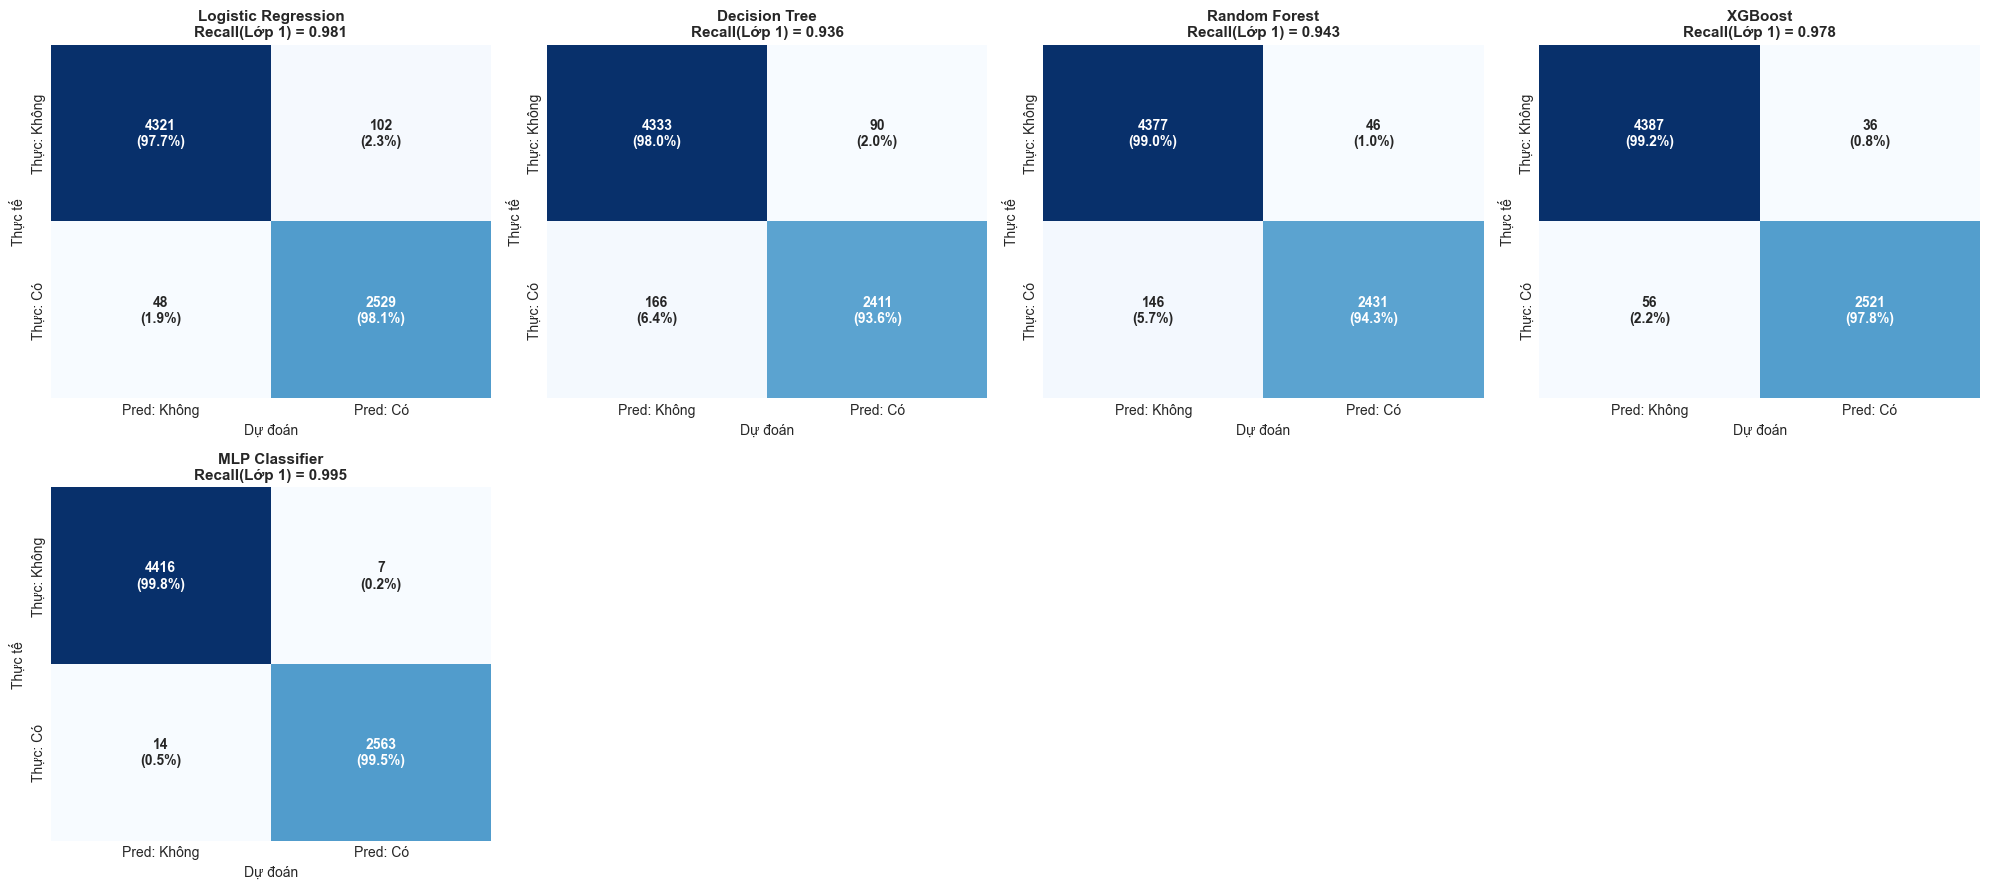

,Model,Accuracy,Precision (lớp 1),Recall (lớp 1),Specificity (lớp 0),F1 (lớp 1),TN,FP,FN,TP
0,MLP Classifier,0.9970,0.9973,0.9946,0.9984,0.9959,4416,7,14,2563
1,XGBoost,0.9869,0.9859,0.9783,0.9919,0.9821,4387,36,56,2521
2,Logistic Regression,0.9786,0.9612,0.9814,0.9769,0.9712,4321,102,48,2529
3,Random Forest,0.9726,0.9814,0.9433,0.9896,0.9620,4377,46,146,2431
4,Decision Tree,0.9634,0.9640,0.9356,0.9797,0.9496,4333,90,166,2411


In [32]:
# ==============================================================================
# PHẦN 8: CONFUSION MATRIX & EVALUATION VISUALIZATION
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score

CLASS_LABELS = ["Không nguy cơ (0)", "Có nguy cơ (1)"]

# Chỉ giữ các pipeline được huấn luyện đúng bộ cột hiện tại của X_test
def _fresh(pipes):
    return {
        n: p for n, p in pipes.items()
        if set(p.named_steps["preprocessor"].feature_names_in_) == set(X_test.columns)
    }

pipelines_to_plot = {}
for var_name, label in [
    ("tuned_best_pipelines", "Phần 10"),
    ("fitted_smote_pipelines", "Phần 7"),
    ("fitted_baseline_pipelines", "Phần 6"),
]:
    if var_name in globals():
        fresh = _fresh(globals()[var_name])
        if fresh:
            pipelines_to_plot = fresh
            print(f"📌 Đang hiển thị đánh giá cho: {var_name} ({label})")
            break

if not pipelines_to_plot:
    raise RuntimeError(
        "Không có pipeline nào khớp với dữ liệu hiện tại. "
        "Hãy Restart kernel và chạy lại từ PHẦN 1."
    )

n_models = len(pipelines_to_plot)

if n_models > 0:
    ncols = min(4, n_models)
    nrows = (n_models + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
    axes = np.array(axes).flatten() if n_models > 1 else np.array([axes])

    for idx, (name, pipeline) in enumerate(pipelines_to_plot.items()):
        y_pred = pipeline.predict(X_test)
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

        cm_sum = cm.sum(axis=1, keepdims=True)
        cm_pct = np.divide(cm, cm_sum, out=np.zeros_like(cm, dtype=float), where=cm_sum != 0)

        annot = np.array([
            [f"{cm[i, j]}\n({cm_pct[i, j] * 100:.1f}%)" for j in range(cm.shape[1])]
            for i in range(cm.shape[0])
        ])

        sns.heatmap(
            cm, annot=annot, fmt="", cmap="Blues", ax=axes[idx], cbar=False,
            xticklabels=["Pred: Không", "Pred: Có"],
            yticklabels=["Thực: Không", "Thực: Có"],
            annot_kws={"size": 10, "weight": "bold"}
        )

        rec_1 = cm[1, 1] / max(cm[1, 0] + cm[1, 1], 1)
        axes[idx].set_title(f"{name}\nRecall(Lớp 1) = {rec_1:.3f}", fontsize=11, fontweight="bold")
        axes[idx].set_xlabel("Dự đoán")
        axes[idx].set_ylabel("Thực tế")

    for j in range(n_models, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

    # Bảng đánh giá chi tiết
    summary_rows = []
    for name, pipeline in pipelines_to_plot.items():
        y_pred = pipeline.predict(X_test)
        cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        specificity = tn / max(tn + fp, 1)

        summary_rows.append({
            "Model": name,
            "Accuracy": round((tp + tn) / max(cm.sum(), 1), 4),
            "Precision (lớp 1)": round(precision_score(y_test, y_pred, zero_division=0), 4),
            "Recall (lớp 1)": round(recall_score(y_test, y_pred, zero_division=0), 4),
            "Specificity (lớp 0)": round(specificity, 4),
            "F1 (lớp 1)": round(f1_score(y_test, y_pred, zero_division=0), 4),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        })

    df_eval = pd.DataFrame(summary_rows).sort_values(by="F1 (lớp 1)", ascending=False).reset_index(drop=True)
    display(df_eval)
    df_eval.to_csv("models/evaluation_summary.csv", index=False)

In [33]:
# ==============================================================================
# PHẦN 9: STRATIFIED K-FOLD CROSS-VALIDATION
# ==============================================================================

import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

print("==========================================")
print("9. THỰC HIỆN 5-FOLD STRATIFIED CROSS VALIDATION")
print("==========================================")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring_metrics = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

cv_results_list = []
models_for_cv = raw_models if "raw_models" in globals() else smote_models

for name, model in models_for_cv.items():
    try:
        if USE_SMOTE:
            steps = [
                ("preprocessor", preprocessor),
                ("smote", SMOTE(sampling_strategy=SMOTE_STRATEGY, random_state=42, k_neighbors=k_neighbors)),
                ("classifier", model),
            ]
        else:
            steps = [
                ("preprocessor", preprocessor),
                ("classifier", model),
            ]

        cv_pipeline = ImbPipeline(steps=steps)

        cv_scores = cross_validate(
            estimator=cv_pipeline,
            X=X_train, y=y_train,
            cv=skf, scoring=scoring_metrics,
            n_jobs=-1, error_score="raise"
        )

        cv_results_list.append({
            "Model": name,
            "CV Accuracy Mean": round(np.mean(cv_scores["test_accuracy"]), 4),
            "CV Precision Mean": round(np.mean(cv_scores["test_precision"]), 4),
            "CV Recall Mean": round(np.mean(cv_scores["test_recall"]), 4),
            "CV F1 Mean": round(np.mean(cv_scores["test_f1"]), 4),
            "CV ROC-AUC Mean": round(np.mean(cv_scores["test_roc_auc"]), 4),
            "CV PR-AUC Mean": round(np.mean(cv_scores["test_average_precision"]), 4),
            "CV PR-AUC Std": round(np.std(cv_scores["test_average_precision"]), 4),
        })
        print(f"✔️ CV hoàn thành: {name}")
    except Exception as e:
        print(f"⚠️ Bỏ qua '{name}': {type(e).__name__}: {e}")

df_cv_results = pd.DataFrame(cv_results_list).sort_values(by=["CV PR-AUC Mean", "CV Recall Mean"], ascending=False).reset_index(drop=True)
display(df_cv_results)

9. THỰC HIỆN 5-FOLD STRATIFIED CROSS VALIDATION
✔️ CV hoàn thành: Logistic Regression
✔️ CV hoàn thành: Decision Tree
✔️ CV hoàn thành: Random Forest
✔️ CV hoàn thành: XGBoost
✔️ CV hoàn thành: MLP Classifier


,Model,CV Accuracy Mean,CV Precision Mean,CV Recall Mean,CV F1 Mean,CV ROC-AUC Mean,CV PR-AUC Mean,CV PR-AUC Std
0,MLP Classifier,0.9968,0.9960,0.9952,0.9956,1.0000,0.9999,0.0000
1,XGBoost,0.9849,0.9761,0.9829,0.9795,0.9991,0.9984,0.0002
2,Logistic Regression,0.9794,0.9658,0.9787,0.9722,0.9985,0.9977,0.0002
3,Random Forest,0.9701,0.9786,0.9393,0.9585,0.9975,0.9957,0.0010
4,Decision Tree,0.9566,0.9572,0.9234,0.9400,0.9496,0.9120,0.0023


In [34]:
# ==============================================================================
# PHẦN 10: HYPERPARAMETER TUNING VỚI RANDOMIZEDSEARCHCV
# ==============================================================================

from sklearn.model_selection import RandomizedSearchCV, ParameterGrid
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score

print("==========================================")
print("10. HYPERPARAMETER TUNING TỐI ƯU HÓA MÔ HÌNH")
print("==========================================")

param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1.0, 10.0],
        "classifier__solver": ["liblinear", "lbfgs"],
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [None, 10, 20],
        "classifier__min_samples_split": [2, 5, 10],
    },
    "XGBoost": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [3, 6, 10],
        "classifier__learning_rate": [0.01, 0.1, 0.2],
    },
}

tune_candidate_models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=42, eval_metric="logloss", verbosity=0),
}
assert all(n in SELECTED_MODELS for n in tune_candidate_models), "Mô hình tuning phải nằm trong 5 mô hình đã chọn"
tuned_best_pipelines = {}
tuning_summary = []

for name, model in tune_candidate_models.items():
    if name not in param_grids:
        continue

    print(f"⏳ Đang tuning: {name}...")

    steps = [
        ("preprocessor", preprocessor),
        ("smote", SMOTE(sampling_strategy=SMOTE_STRATEGY, random_state=42, k_neighbors=k_neighbors)) if USE_SMOTE else None,
        ("classifier", model),
    ]
    steps = [s for s in steps if s is not None]
    pipeline = ImbPipeline(steps=steps)

    n_iter = min(10, len(ParameterGrid(param_grids[name])))

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grids[name],
        n_iter=n_iter,
        scoring="average_precision",
        cv=skf, random_state=42, n_jobs=-1, error_score="raise"
    )

    try:
        search.fit(X_train, y_train)
        best_pipe = search.best_estimator_

        y_pred = best_pipe.predict(X_test)
        y_proba = best_pipe.predict_proba(X_test)[:, 1] if hasattr(best_pipe, "predict_proba") else best_pipe.decision_function(X_test)

        tuned_best_pipelines[name] = best_pipe
        tuning_summary.append({
            "Model": name,
            "Best CV PR-AUC": round(search.best_score_, 4),
            "Test PR-AUC": round(average_precision_score(y_test, y_proba), 4),
            "Test F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
            "Test ROC-AUC": round(roc_auc_score(y_test, y_proba), 4),
            "Best Params": search.best_params_,
        })
        print(f"✔️ {name} | Best CV PR-AUC = {search.best_score_:.4f}")
    except Exception as e:
        print(f"⚠️ Bỏ qua tuning '{name}': {type(e).__name__}: {e}")

df_tuning = pd.DataFrame(tuning_summary).sort_values(by="Best CV PR-AUC", ascending=False).reset_index(drop=True)
display(df_tuning)

10. HYPERPARAMETER TUNING TỐI ƯU HÓA MÔ HÌNH
⏳ Đang tuning: Logistic Regression...
✔️ Logistic Regression | Best CV PR-AUC = 0.9977
⏳ Đang tuning: Random Forest...
✔️ Random Forest | Best CV PR-AUC = 0.9957
⏳ Đang tuning: XGBoost...
✔️ XGBoost | Best CV PR-AUC = 0.9990


,Model,Best CV PR-AUC,Test PR-AUC,Test F1,Test ROC-AUC,Best Params
0,XGBoost,0.9990,0.9990,0.9831,0.9994,"{'classifier__n_estimators': 200, 'classifier_..."
1,Logistic Regression,0.9977,0.9975,0.9701,0.9984,"{'classifier__solver': 'lbfgs', 'classifier__C..."
2,Random Forest,0.9957,0.9965,0.9620,0.9980,"{'classifier__n_estimators': 100, 'classifier_..."


🏆 MÔ HÌNH ĐƯỢC CHỌN CUỐI CÙNG: XGBOOST


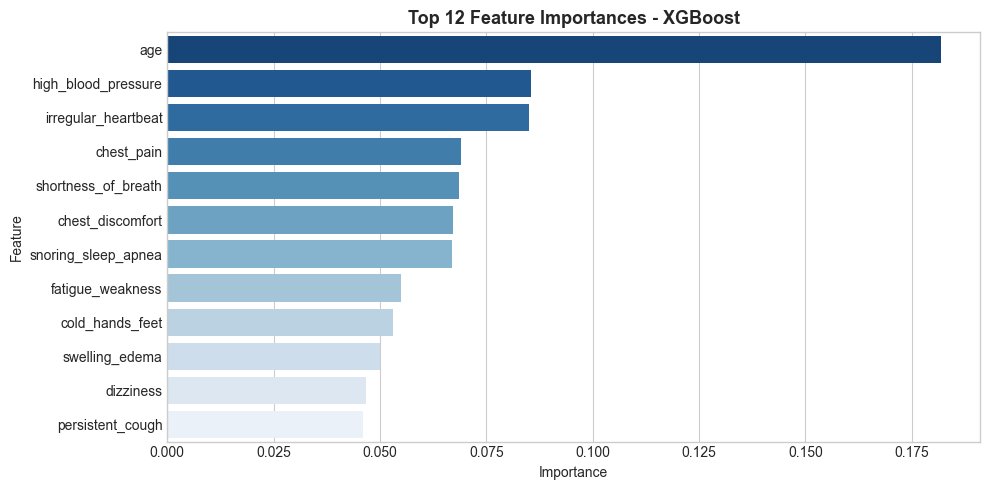

🎯 Ngưỡng quyết định tối ưu cho Recall (95%): 0.8487
              precision    recall  f1-score   support

Nguy cơ thấp       0.97      1.00      0.99      4423
 Nguy cơ cao       1.00      0.95      0.97      2577

    accuracy                           0.98      7000
   macro avg       0.98      0.98      0.98      7000
weighted avg       0.98      0.98      0.98      7000

Confusion matrix:
 [[4413   10]
 [ 118 2459]]
PR-AUC : 0.9992
ROC-AUC: 0.9995
Brier  : 0.0084

🎉 XUẤT FILE THÀNH CÔNG!
  🏆 Mô hình cuối cùng : XGBoost
  🎯 Ngưỡng quyết định : 0.8487 (84.87%)
  📈 Recall trên test  : 0.9542
  📈 PR-AUC trên test  : 0.9992
  ✔️ models/stroke_model.pkl
  ✔️ models/threshold.json
  ✔️ models/summary.json


In [36]:
# ==============================================================================
# PHẦN 11: CALIBRATION, FEATURE IMPORTANCE & XUẤT MÔ HÌNH CUỐI CÙNG
# ==============================================================================

import json, os, joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, precision_recall_curve,
    brier_score_loss, classification_report, confusion_matrix
)

# 11.1. CHỌN MÔ HÌNH XUẤT SẮC NHẤT
best_model_name = df_tuning.iloc[0]["Model"] if "df_tuning" in globals() and len(df_tuning) > 0 else "Random Forest"
final_pipeline = tuned_best_pipelines.get(best_model_name, list(fitted_smote_pipelines.values())[0])

print(f"🏆 MÔ HÌNH ĐƯỢC CHỌN CUỐI CÙNG: {best_model_name.upper()}")

# 11.2. FEATURE IMPORTANCE
clf = final_pipeline.named_steps["classifier"]
try:
    raw_names = final_pipeline.named_steps["preprocessor"].get_feature_names_out()
    feature_names = [n.split("__", 1)[1] for n in raw_names]
except Exception:
    feature_names = [f"feature_{i}" for i in range(X_train.shape[1])]

if hasattr(clf, "feature_importances_"):
    importances = clf.feature_importances_
elif hasattr(clf, "coef_"):
    importances = np.abs(clf.coef_[0])
else:
    importances = np.zeros(len(feature_names))

feat_imp_df = pd.DataFrame({"Feature": feature_names, "Importance": importances}).sort_values(by="Importance", ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 5))
sns.barplot(x="Importance", y="Feature", data=feat_imp_df.head(12), palette="Blues_r", hue="Feature", legend=False)
plt.title(f"Top 12 Feature Importances - {best_model_name}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

TARGET_RECALL = 0.95   # đổi từ 0.80

calibrated_model = CalibratedClassifierCV(final_pipeline, method="sigmoid", cv=5)
calibrated_model.fit(X_train, y_train)

oof_proba = cross_val_predict(
    CalibratedClassifierCV(final_pipeline, method="sigmoid", cv=5),
    X_train, y_train, cv=skf, method="predict_proba", n_jobs=-1
)[:, 1]

prec_c, rec_c, thr_c = precision_recall_curve(y_train, oof_proba)
ok = np.where(rec_c[:-1] >= TARGET_RECALL)[0]
decision_threshold = float(thr_c[ok[-1]]) if len(ok) > 0 else 0.5

print(f"🎯 Ngưỡng quyết định tối ưu cho Recall ({TARGET_RECALL*100:.0f}%): {decision_threshold:.4f}")

# ĐÁNH GIÁ CUỐI CÙNG TRÊN TẬP TEST (đã calibrate + ngưỡng)
y_test_proba = calibrated_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_proba >= decision_threshold).astype(int)

print(classification_report(y_test, y_test_pred, target_names=["Nguy cơ thấp", "Nguy cơ cao"], zero_division=0))
print("Confusion matrix:\n", confusion_matrix(y_test, y_test_pred))
print(f"PR-AUC : {average_precision_score(y_test, y_test_proba):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_test_proba):.4f}")
print(f"Brier  : {brier_score_loss(y_test, y_test_proba):.4f}")
# 11.4. LƯU MÔ HÌNH VÀ THÔNG TIN CẤU HÌNH ĐỒNG BỘ
for folder in ["models", "../models"]:
    os.makedirs(folder, exist_ok=True)
    
    # 1. Lưu Pipeline Mô hình đã Calibrate
    joblib.dump(calibrated_model, f"{folder}/stroke_model.pkl")
    
    # 2. Lưu Threshold Config
    with open(f"{folder}/threshold.json", "w", encoding="utf-8") as f:
        json.dump({
            "threshold": decision_threshold,
            "target_recall": TARGET_RECALL,
            "model": best_model_name,
            "target_column": TARGET_COL
        }, f, ensure_ascii=False, indent=2)

    # 3. Lưu Summary Config
    y_test_proba = calibrated_model.predict_proba(X_test)[:, 1]
    y_test_pred = (y_test_proba >= decision_threshold).astype(int)
    
    with open(f"{folder}/summary.json", "w", encoding="utf-8") as f:
        json.dump({
            "target_column": TARGET_COL,
            "best_model": best_model_name,
            "threshold": decision_threshold,
            "metrics": {
                "Accuracy": float(accuracy_score(y_test, y_test_pred)),
                "Precision": float(precision_score(y_test, y_test_pred, zero_division=0)),
                "Recall": float(recall_score(y_test, y_test_pred, zero_division=0)),
                "F1": float(f1_score(y_test, y_test_pred, zero_division=0)),
                "ROC-AUC": float(roc_auc_score(y_test, y_test_proba)),
                "PR-AUC": float(average_precision_score(y_test, y_test_proba)),
            }
        }, f, ensure_ascii=False, indent=2)

print("\n🎉 XUẤT FILE THÀNH CÔNG!")
print(f"  🏆 Mô hình cuối cùng : {best_model_name}")
print(f"  🎯 Ngưỡng quyết định : {decision_threshold:.4f} ({decision_threshold*100:.2f}%)")
print(f"  📈 Recall trên test  : {recall_score(y_test, y_test_pred, zero_division=0):.4f}")
print(f"  📈 PR-AUC trên test  : {average_precision_score(y_test, y_test_proba):.4f}")
print("  ✔️ models/stroke_model.pkl")
print("  ✔️ models/threshold.json")
print("  ✔️ models/summary.json")